# Prepoznavanje melanoma na dermatoskopskim slikama primjenom prijenosnog učenja
**Verzija 2** – odluke verzije 2 zapisane prije njezine evaluacije (vidi `Plan_v2.md` i `DNEVNIK_EKSPERIMENATA.md`).
Edukacijski projekt, nije namijenjen kliničkoj uporabi.

**Sadržaj:** 1. Postavke · 2–3. EDA (HAM10000, HIBA) · 4. Podjela po leziji · 5. Treniranje · 6. Evaluacija i prag · 7. Vanjska provjera HIBA · 8. Analiza pogrešaka · 9. Grad-CAM · 10. BCN20000 · 11. Demo · 12. requirements.txt · 13. Dodatne analize · 14. Usporedni modeli · 15. Zaključak i ograničenja

**Kako pokretati:**
- **Demo (obrana):** pokrenuti samo ćeliju 1, zatim ćeliju 11.
- **Dodatne analize:** ćelija 1, zatim ćelije 13b–13k redom.
- **Usporedni modeli:** ćelija 1, 13b–13e, zatim 14a–14h (dugi treninzi – najbolje u VS Code terminalu).
- **NE koristiti „Run All”** – ponovno bi se pokrenula podjela, treniranje (~50 min) i sve evaluacije.

## 1. Postavke i provjera okruženja

In [1]:
# ===== 1. POSTAVKE I PROVJERA OKRUŽENJA =====
import sys                                    # podaci o Pythonu (verzija)
import json                                   # čitanje i pisanje JSON datoteka (prag.json)
from pathlib import Path                      # putanje do mapa i datoteka (rade i na Windowsima)

import numpy as np                            # rad s brojevima i nizovima
import pandas as pd                           # tablice (DataFrame)
import matplotlib                             # biblioteka za grafove (ovdje samo za ispis verzije)
import matplotlib.pyplot as plt               # crtanje grafova
import PIL                                    # biblioteka za slike (ovdje samo za ispis verzije)
from PIL import Image                         # otvaranje slika
import sklearn                                # scikit-learn (ovdje samo za ispis verzije)
import torch                                  # PyTorch – duboko učenje
import torchvision                            # slike, transformacije i gotovi modeli za PyTorch

# --- zajedničke postavke cijele bilježnice ---
SEED = 42                                     # isti "slučajni" izbor pri svakom pokretanju (ponovljivost)
DATA_ROOT = Path("data")                      # mapa s izvornim podacima
HAM_DIR = DATA_ROOT / "ham10000"              # HAM10000 – trening, validacija i test
HIBA_DIR = DATA_ROOT / "hiba"                 # HIBA – vanjska provjera (Buenos Aires)
BCN_DIR = DATA_ROOT / "bcn20000"              # BCN20000 – završni neovisni test (Barcelona)
REZ = Path("rezultati")                       # svi rezultati verzije 2
EDA_DIR = REZ / "eda"                         # rezultati istraživanja podataka (EDA)
EDA_DIR.mkdir(parents=True, exist_ok=True)    # napravi mapu ako još ne postoji

# --- verzije (za README i requirements.txt) ---
print("Python      :", sys.version.split()[0])           # verzija Pythona
print("PyTorch     :", torch.__version__)                # verzija PyTorcha
print("torchvision :", torchvision.__version__)          # verzija torchvisiona
print("scikit-learn:", sklearn.__version__)              # verzija scikit-learna
print("pandas      :", pd.__version__)                   # verzija pandasa
print("numpy       :", np.__version__)                   # verzija numpyja
print("matplotlib  :", matplotlib.__version__)           # verzija matplotliba
print("Pillow      :", PIL.__version__)                  # verzija Pillowa
print("Uređaj      :", "cuda" if torch.cuda.is_available() else "cpu", "| CPU dretve:", torch.get_num_threads())   # GPU ili CPU

# --- jesu li podaci na mjestu i je li stara verzija sklonjena ---
for mapa in [HAM_DIR, HIBA_DIR, BCN_DIR]:                  # za svaku mapu s podacima
    print(f"{str(mapa):15} postoji: {mapa.exists()}")      # True = mapa je na mjestu
print("\nU mapi projekta:", sorted(p.name for p in Path(".").iterdir()))   # popis svega u mapi projekta

Python      : 3.12.15
PyTorch     : 2.14.1+cpu
torchvision : 0.29.1+cpu
scikit-learn: 1.9.1
pandas      : 3.1.1
numpy       : 2.5.3
matplotlib  : 3.11.2
Pillow      : 12.3.0
Uređaj      : cpu | CPU dretve: 12
data\ham10000   postoji: True
data\hiba       postoji: True
data\bcn20000   postoji: True

U mapi projekta: ['__pycache__', 'arhiva_v1', 'data', 'data_split', 'evaluate_bcn.py', 'evaluate_hiba.py', 'evaluate_melanom.py', 'melanom_v2.ipynb', 'melanom_v2_prije_usporedbi.ipynb', 'podijeli_ham.py', 'requirements.txt', 'rezultati', 'runs', 'train_melanom.py']


## 2. Istraživanje podataka (EDA) – HAM10000

In [2]:
# ===== 2a. EDA HAM10000 – tablica metapodataka =====
ham = pd.read_csv(HAM_DIR / "HAM10000_metadata.csv")      # učitaj tablicu: jedna slika = jedan redak
ham["melanom"] = (ham["dx"] == "mel").astype(int)          # nova oznaka: 1 = melanom, 0 = ostalo

print("Oblik tablice (redaka, stupaca):", ham.shape)        # broj redaka i stupaca
print("Broj slika :", ham["image_id"].nunique())            # broj različitih slika
print("Broj lezija:", ham["lesion_id"].nunique())           # broj različitih lezija (neke imaju više slika)
print("\nNedostajuće vrijednosti:\n", ham.isnull().sum())   # broj praznih polja po stupcu

print("\nDijagnoze (broj slika):\n", ham["dx"].value_counts())       # slike po dijagnozi
print("\nMelanom – slike:\n", ham["melanom"].value_counts())         # melanom / ostalo – po slikama
print("\nMelanom – lezije:\n", ham.groupby("lesion_id")["melanom"].first().value_counts())   # isto, po lezijama

# provjera: ima li ista lezija više dijagnoza? (ne smije – inače podjela po leziji nema smisla)
print("\nLezija s više dijagnoza:", (ham.groupby("lesion_id")["dx"].nunique() > 1).sum())

# način potvrde dijagnoze po dijagnozi (ograničenje: nevusi često bez histologije)
potvrda = pd.crosstab(ham["dx"], ham["dx_type"], margins=True, margins_name="ukupno")   # dijagnoza × način potvrde
print("\nDijagnoza × način potvrde:\n", potvrda)            # ispiši tablicu
potvrda.to_csv(EDA_DIR / "ham_dijagnoza_x_potvrda.csv")     # spremi tablicu za README/prezentaciju

# provjera datoteka i veličine slika
ham_putanje = {p.stem: p for p in HAM_DIR.rglob("*.jpg")}   # kazalo: image_id -> putanja do slike
print("\nSlika na disku:", len(ham_putanje), "| iz tablice bez datoteke:",
      len(set(ham["image_id"]) - set(ham_putanje)))        # slike iz tablice kojih nema na disku (mora biti 0)
velicine = pd.Series([Image.open(p).size for p in ham_putanje.values()])   # (širina, visina) svake slike
print("Veličine slika (širina, visina):\n", velicine.value_counts())       # koliko slika koje veličine

Oblik tablice (redaka, stupaca): (10015, 8)
Broj slika : 10015
Broj lezija: 7470

Nedostajuće vrijednosti:
 lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
melanom          0
dtype: int64

Dijagnoze (broj slika):
 dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Melanom – slike:
 melanom
0    8902
1    1113
Name: count, dtype: int64

Melanom – lezije:
 melanom
0    6856
1     614
Name: count, dtype: int64

Lezija s više dijagnoza: 0

Dijagnoza × način potvrde:
 dx_type  confocal  consensus  follow_up  histo  ukupno
dx                                                    
akiec           0          0          0    327     327
bcc             0          0          0    514     514
bkl            69        264          0    766    1099
df              0         60          0     55     115
mel             0          0          0 

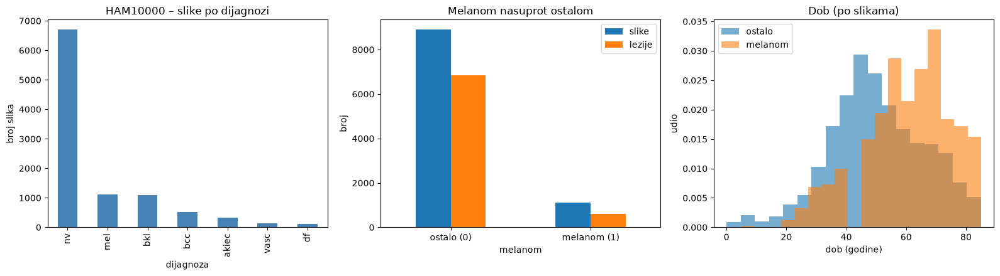

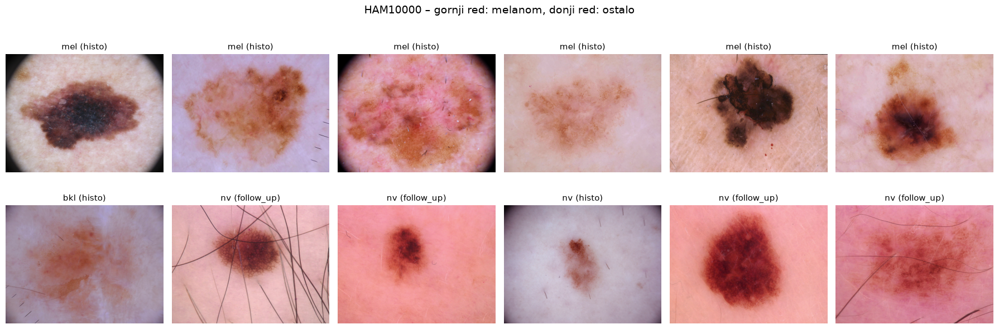

In [4]:
# ===== 2b. EDA HAM10000 – grafovi i primjeri =====
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))          # tri grafa u jednom redu

# 1) broj slika po dijagnozi
ham["dx"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")   # stupčasti graf
axes[0].set_title("HAM10000 – slike po dijagnozi")         # naslov
axes[0].set_xlabel("dijagnoza")                            # oznaka x-osi
axes[0].set_ylabel("broj slika")                           # oznaka y-osi

# 2) melanom nasuprot ostalom – slike i lezije
lezije = ham.groupby("lesion_id")["melanom"].first()       # jedna oznaka po leziji
usporedba = pd.DataFrame({"slike": ham["melanom"].value_counts(), "lezije": lezije.value_counts()})   # slike i lezije jedno uz drugo
usporedba = usporedba.rename(index={0: "ostalo (0)", 1: "melanom (1)"})   # čitljiviji nazivi redaka
usporedba.plot(kind="bar", ax=axes[1], rot=0)              # stupčasti graf, natpisi vodoravno
axes[1].set_title("Melanom nasuprot ostalom")              # naslov
axes[1].set_ylabel("broj")                                 # oznaka y-osi

# 3) dob – udio, jer je melanoma ~8x manje
ham[ham["melanom"] == 0]["age"].plot(kind="hist", bins=18, alpha=0.6, density=True, ax=axes[2], label="ostalo")    # dob – ostalo
ham[ham["melanom"] == 1]["age"].plot(kind="hist", bins=18, alpha=0.6, density=True, ax=axes[2], label="melanom")   # dob – melanom
axes[2].set_title("Dob (po slikama)")                      # naslov
axes[2].set_xlabel("dob (godine)")                         # oznaka x-osi
axes[2].set_ylabel("udio")                                 # oznaka y-osi
axes[2].legend()                                           # legenda (ostalo / melanom)

plt.tight_layout()                                         # razmakni grafove da se ne preklapaju
plt.savefig(EDA_DIR / "ham_pregled.png", dpi=150)          # spremi sliku za prezentaciju
plt.show()                                                 # prikaži

# primjeri: po jedna slika po leziji, 6 melanoma (gore) i 6 ostalih (dolje)
jedna_po_leziji = ham.drop_duplicates(subset="lesion_id")  # samo prva slika svake lezije
primjeri = pd.concat([jedna_po_leziji[jedna_po_leziji["melanom"] == 1].sample(6, random_state=SEED),    # 6 nasumičnih melanoma
                      jedna_po_leziji[jedna_po_leziji["melanom"] == 0].sample(6, random_state=SEED)])   # 6 nasumičnih ostalih

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))          # mreža 2 × 6 slika
for ax, (_, red) in zip(axes.flatten(), primjeri.iterrows()):   # za svaku sliku i njezino mjesto u mreži
    ax.imshow(Image.open(ham_putanje[red["image_id"]]))    # otvori i prikaži sliku
    ax.set_title(f'{red["dx"]} ({red["dx_type"]})', fontsize=11)   # naslov: dijagnoza (način potvrde)
    ax.axis("off")                                         # bez osi
plt.suptitle("HAM10000 – gornji red: melanom, donji red: ostalo", fontsize=14)   # glavni naslov
plt.tight_layout()                                         # razmakni slike
plt.savefig(EDA_DIR / "ham_primjeri.png", dpi=150)         # spremi
plt.show()                                                 # prikaži

## 3. Istraživanje podataka (EDA) – HIBA (vanjska provjera)

In [6]:
# ===== 3a. EDA HIBA – samo dermatoskopske slike =====
hiba_sve = pd.read_csv(HIBA_DIR / "metadata.csv")                   # cijela HIBA tablica
print("Sve slike u tablici:", len(hiba_sve))                         # broj svih slika
print("Vrste slika:\n", hiba_sve["image_type"].value_counts())       # dermatoskopske / kliničke

hiba = hiba_sve[hiba_sve["image_type"] == "dermoscopic"].copy()     # koristimo SAMO dermatoskopske
hiba["melanom"] = (hiba["diagnosis"] == "melanoma").astype(int)     # 1 = melanom, 0 = ostalo

print("\nDermatoskopskih slika:", len(hiba))                         # broj slika
print("Lezija    :", hiba["lesion_id"].nunique())                    # broj lezija
print("Pacijenata:", hiba["patient_id"].nunique())                   # broj pacijenata (HIBA ga ima, HAM nema)
print("\nMelanom – slike:\n", hiba["melanom"].value_counts())        # melanom / ostalo – po slikama
print("\nMelanom – lezije:\n", hiba.groupby("lesion_id")["melanom"].first().value_counts())   # isto, po lezijama
print("\nDijagnoze:\n", hiba["diagnosis"].value_counts())            # slike po dijagnozi
print("\nPotvrda kod melanoma:\n", hiba[hiba["melanom"] == 1]["diagnosis_confirm_type"].value_counts(dropna=False))   # kako je melanom potvrđen

# tip kože (Fitzpatrick) × melanom – važno za pitanje o svijetloj i tamnoj koži
koza = pd.crosstab(hiba["fitzpatrick_skin_type"].fillna("nema podatka"), hiba["melanom"],
                   margins=True, margins_name="ukupno")             # tip kože × melanom, sa zbrojevima
print("\nTip kože × melanom:\n", koza)                               # ispiši tablicu
koza.to_csv(EDA_DIR / "hiba_tip_koze_x_melanom.csv")                # spremi tablicu

# datoteke i veličine slika
hiba_putanje = {p.stem: p for p in HIBA_DIR.rglob("*.jpg")}         # kazalo: isic_id -> putanja do slike
print("\nIma li svaka slika datoteku:", hiba["isic_id"].isin(hiba_putanje.keys()).all())   # mora biti True
velicine = pd.Series([Image.open(hiba_putanje[i]).size for i in hiba["isic_id"]])         # (širina, visina) svake slike
print("Broj različitih veličina slika:", velicine.nunique())        # HIBA slike su različitih veličina
print("Najčešće veličine:\n", velicine.value_counts().head(5))       # 5 najčešćih veličina

Sve slike u tablici: 1635
Vrste slika:
 image_type
dermoscopic           1280
clinical: overview     349
clinical: close-up       6
Name: count, dtype: int64

Dermatoskopskih slika: 1280
Lezija    : 1201
Pacijenata: 589

Melanom – slike:
 melanom
0    1084
1     196
Name: count, dtype: int64

Melanom – lezije:
 melanom
0    1042
1     159
Name: count, dtype: int64

Dijagnoze:
 diagnosis
nevus                      555
basal cell carcinoma       230
melanoma                   196
squamous cell carcinoma    111
seborrheic keratosis        47
actinic keratosis           46
vascular lesion             41
dermatofibroma              39
solar lentigo               14
lichenoid keratosis          1
Name: count, dtype: int64

Potvrda kod melanoma:
 diagnosis_confirm_type
histopathology    196
Name: count, dtype: int64

Tip kože × melanom:
 melanom                   0    1  ukupno
fitzpatrick_skin_type                   
I                        72   25      97
II                      660  144  

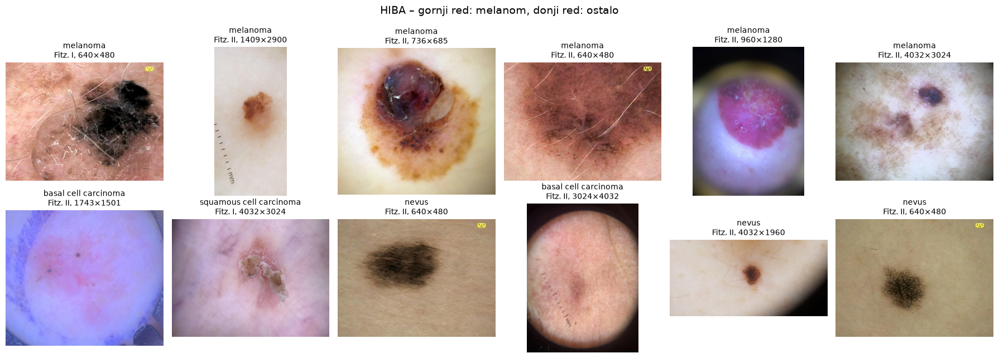

In [7]:
# ===== 3b. EDA HIBA – primjeri slika =====
jedna_po_leziji = hiba.drop_duplicates(subset="lesion_id")          # samo prva slika svake lezije
primjeri = pd.concat([jedna_po_leziji[jedna_po_leziji["melanom"] == 1].sample(6, random_state=SEED),    # 6 nasumičnih melanoma
                      jedna_po_leziji[jedna_po_leziji["melanom"] == 0].sample(6, random_state=SEED)])   # 6 nasumičnih ostalih

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))                   # mreža 2 × 6 slika
for ax, (_, red) in zip(axes.flatten(), primjeri.iterrows()):       # za svaku sliku i njezino mjesto u mreži
    slika = Image.open(hiba_putanje[red["isic_id"]])                 # otvori sliku
    ax.imshow(slika)                                                 # prikaži sliku
    ax.set_title(f'{red["diagnosis"]}\nFitz. {red["fitzpatrick_skin_type"]}, {slika.size[0]}×{slika.size[1]}', fontsize=10)   # dijagnoza, tip kože, veličina
    ax.axis("off")                                                   # bez osi
plt.suptitle("HIBA – gornji red: melanom, donji red: ostalo", fontsize=14)   # glavni naslov
plt.tight_layout()                                                   # razmakni slike
plt.savefig(EDA_DIR / "hiba_primjeri.png", dpi=150)                  # spremi
plt.show()                                                           # prikaži

## 4. Podjela HAM10000 na trening / validaciju / test (po leziji)

In [9]:
%%writefile podijeli_ham.py
#
# PODJELA HAM10000 NA TRENING (70 %), VALIDACIJU (15 %) I TEST (15 %) – PO LEZIJI
# Sve slike iste lezije idu u isti skup (inače bi model na testu "prepoznao" lezije iz treninga).
# Stratificirano po melanomu: u svakom skupu podjednak udio melanoma.
# Slike se kopiraju u data_split/<skup>/<klasa>, da ImageFolder radi kao u prošlom projektu.
#
import shutil                                          # kopiranje datoteka
from pathlib import Path                               # putanje do mapa i datoteka

import pandas as pd                                    # tablice
from sklearn.model_selection import train_test_split  # stratificirana podjela (DL6, ML)


#                             POSTAVKE
HAM_DIR = Path("data") / "ham10000"                    # izvorne HAM10000 slike
HAM_CSV = HAM_DIR / "HAM10000_metadata.csv"            # tablica metapodataka
SPLIT_DIR = Path("data_split")                         # ovdje nastaju mape za ImageFolder
PODJELA_CSV = Path("rezultati") / "podjela_ham.csv"    # popis: koja slika je u kojem skupu
VAL_RATIO = 0.15                                       # 15 % lezija za validaciju
TEST_RATIO = 0.15                                      # 15 % lezija za test
SEED = 42                                              # ista podjela pri svakom pokretanju
MAPE_KLASA = {0: "0_ostalo", 1: "1_melanom"}           # broj ispred imena -> ImageFolder daje melanomu indeks 1


def main():
    if SPLIT_DIR.exists():                                # zaštita: ne dijeli dvaput
        print("Mapa data_split već postoji – podjela je već napravljena.")
        return                                            # izlaz iz funkcije, ništa se ne mijenja

    # 1) učitavanje i oznaka melanoma
    ham = pd.read_csv(HAM_CSV)                            # jedna slika = jedan redak
    ham["melanom"] = (ham["dx"] == "mel").astype(int)     # 1 = melanom, 0 = ostalo

    # 2) tablica LEZIJA: jedan redak = jedna lezija (sve njezine slike imaju istu dijagnozu)
    lezije = ham.groupby("lesion_id")["melanom"].first().reset_index()

    # 3) dijelimo lezije: prvo 15 % za test, pa iz ostatka 15 % svih lezija za validaciju
    ostatak, test = train_test_split(lezije, test_size=TEST_RATIO,
                                     stratify=lezije["melanom"], random_state=SEED)   # odvoji test
    val_udio = VAL_RATIO / (1 - TEST_RATIO)            # 0.15 / 0.85 ≈ 0.176 ostatka = 15 % svih
    train, val = train_test_split(ostatak, test_size=val_udio,
                                  stratify=ostatak["melanom"], random_state=SEED)     # ostatak -> trening i validacija

    # 4) svaka slika dobiva skup svoje lezije
    ham["skup"] = ""                                                           # prazan stupac
    ham.loc[ham["lesion_id"].isin(train["lesion_id"]), "skup"] = "train"       # slike trening lezija
    ham.loc[ham["lesion_id"].isin(val["lesion_id"]), "skup"] = "val"           # slike validacijskih lezija
    ham.loc[ham["lesion_id"].isin(test["lesion_id"]), "skup"] = "test"         # slike testnih lezija

    # 5) provjera: nijedna lezija ne smije biti u dva skupa
    skupova_po_leziji = ham.groupby("lesion_id")["skup"].nunique()             # u koliko skupova je svaka lezija
    if (skupova_po_leziji > 1).sum() > 0 or (ham["skup"] == "").sum() > 0:     # lezija u 2 skupa ili slika bez skupa
        raise ValueError("Greška u podjeli: lezija u više skupova ili slika bez skupa!")   # zaustavi program
    print("Provjera: svaka lezija je u točno jednom skupu. OK\n")

    # 6) pregled: slike i lezije po skupu i klasi
    print("SLIKE po skupu (0 = ostalo, 1 = melanom):")
    print(pd.crosstab(ham["skup"], ham["melanom"], margins=True, margins_name="ukupno"))   # skup × klasa – slike
    lez = ham.drop_duplicates(subset="lesion_id")                                         # jedan redak po leziji
    print("\nLEZIJE po skupu (0 = ostalo, 1 = melanom):")
    print(pd.crosstab(lez["skup"], lez["melanom"], margins=True, margins_name="ukupno"))   # skup × klasa – lezije

    # 7) spremi popis podjele (ponovljivost)
    PODJELA_CSV.parent.mkdir(parents=True, exist_ok=True)                                          # napravi mapu rezultati
    ham[["image_id", "lesion_id", "dx", "dx_type", "melanom", "skup"]].to_csv(PODJELA_CSV, index=False)   # spremi popis
    print(f"\nPopis podjele spremljen: {PODJELA_CSV}")

    # 8) kopiraj slike u data_split/<skup>/<klasa>/ (izvornici ostaju)
    putanje = {p.stem: p for p in HAM_DIR.rglob("*.jpg")}                      # kazalo: image_id -> putanja
    for _, red in ham.iterrows():                                              # za svaku sliku
        odrediste = SPLIT_DIR / red["skup"] / MAPE_KLASA[red["melanom"]]       # npr. data_split/train/1_melanom
        odrediste.mkdir(parents=True, exist_ok=True)                           # napravi mapu ako ne postoji
        shutil.copy(putanje[red["image_id"]], odrediste / f'{red["image_id"]}.jpg')   # kopiraj sliku

    print("\nBroj slika po mapi:")
    for mapa in sorted(SPLIT_DIR.glob("*/*")):                                 # svaka mapa skup/klasa
        print(f"   {mapa}: {len(list(mapa.glob('*.jpg')))}")                   # broj slika u njoj
    print("Gotovo.")


if __name__ == "__main__":     # pokreće se samo kad skriptu pokrenemo izravno (python podijeli_ham.py)
    main()

Overwriting podijeli_ham.py


In [10]:
# pokreni podjelu – SAMO JEDNOM (ako data_split postoji, skripta ništa ne mijenja)
!python -u podijeli_ham.py

Mapa data_split već postoji – podjela je već napravljena.


## 5. Treniranje – transfer learning s ResNet-18

In [11]:
%%writefile train_melanom.py
#
# Trening modela za prepoznavanje melanoma – transfer learning s ResNet-18
# Tijek: slike iz data_split/train i data_split/val (već podijeljene PO LEZIJI)
# - augmentacija samo u treningu - ResNet-18, novi zadnji sloj 512 -> 2
# - gubitak s težinama klasa (melanoma je ~8x manje) - nakon svake epohe validacija:
#   AUC, osjetljivost i specifičnost - spremam model s NAJBOLJIM validacijskim AUC-om
#
import time                                               # mjerenje trajanja epohe
from pathlib import Path                                  # putanje do mapa i datoteka
from typing import Tuple                                  # oznaka tipa: funkcija vraća više vrijednosti

import torch                                              # PyTorch
import torch.nn as nn                                     # slojevi mreže i funkcije gubitka
from torch.utils.data import DataLoader                   # slaže slike u batcheve
from torch.utils.tensorboard import SummaryWriter         # zapis tijeka učenja za TensorBoard
from torchvision import transforms                        # obrada i augmentacija slika
from torchvision.datasets import ImageFolder              # čita slike iz mapa po klasama
from torchvision.models import resnet18, ResNet18_Weights # ResNet-18 i njegove ImageNet težine
from sklearn.metrics import roc_auc_score                 # AUC iz vjerojatnosti (ML5)


#
# GLOBALNE POSTAVKE
#
PROBNI_RAD = False          # True = kratki probni pokretaj; False = pravo treniranje

TRAIN_DIR = Path("data_split") / "train"                  # trening slike
VAL_DIR = Path("data_split") / "val"                      # validacijske slike
RUN_DIR = Path("runs") / ("melanom_probni" if PROBNI_RAD else "melanom_resnet18")   # kamo se sprema model

EPOCHS = 1 if PROBNI_RAD else 10           # broj prolazaka kroz sve trening slike
MAX_BATCHES = 30 if PROBNI_RAD else None   # probni rad: samo prvih 30 batcheva
BATCH_SIZE = 32            # broj slika u jednom koraku učenja
LEARNING_RATE = 1e-4       # mala stopa učenja: fino podešavanje već naučene mreže
NUM_WORKERS = 4            # pomoćni procesi za učitavanje slika
SEED = 42                  # ponovljivost
LOG_EVERY = 10             # svakih 10 batcheva zapiši gubitak u TensorBoard
MELANOM = 1                # indeks klase melanom (mapa 1_melanom)


def set_seed(seed: int):
    torch.manual_seed(seed)              # iste početne težine novog sloja i isto miješanje slika
    torch.cuda.manual_seed_all(seed)     # isto za GPU (ovdje ga nemamo, ne smeta)


def make_dataloaders_with_imagefolder() -> Tuple[DataLoader, DataLoader, list, torch.Tensor]:
    for mapa in [TRAIN_DIR, VAL_DIR]:                                  # provjeri postoje li mape
        if not mapa.exists():
            raise FileNotFoundError(f"Ne nalazim: {mapa} – prvo pokreni podijeli_ham.py")

    weights = ResNet18_Weights.DEFAULT                                 # ImageNet težine (i njihova normalizacija)

    # Trening: augmentacija – lezija nema "gore", a boja je dijagnostički važna
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),   # nasumičan izrez i povećanje
        transforms.RandomHorizontalFlip(p=0.5),                 # zrcaljenje lijevo-desno
        transforms.RandomVerticalFlip(p=0.5),                   # zrcaljenje gore-dolje
        transforms.RandomRotation(30),                          # zakretanje do 30 stupnjeva
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),  # blago: razlike kamera
        transforms.ToTensor(),                                  # slika -> tenzor (brojevi 0–1)
        transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),   # kao kod ImageNeta
    ])

    # Validacija: bez augmentacije; Resize(256) + CenterCrop(224) čuva omjer stranica
    val_transform = transforms.Compose([
        transforms.Resize(256),                                 # kraća stranica -> 256 piksela
        transforms.CenterCrop(224),                             # središnji izrez 224 × 224
        transforms.ToTensor(),                                  # slika -> tenzor
        transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),   # ista normalizacija
    ])

    # Skupovi su već podijeljeni po leziji u zasebne mape – zato nema random_split
    train_ds = ImageFolder(root=str(TRAIN_DIR), transform=train_transform)   # trening slike + oznake iz imena mapa
    val_ds = ImageFolder(root=str(VAL_DIR), transform=val_transform)         # validacijske slike

    print("Klase:", train_ds.class_to_idx)            # očekujem {'0_ostalo': 0, '1_melanom': 1}
    if train_ds.class_to_idx["1_melanom"] != MELANOM:  # zaštita: melanom mora imati indeks 1
        raise ValueError("Melanom nema indeks 1!")

    # Težine klasa – SAMO iz trening skupa: n / (broj_klasa × n_klase)  (DL6, ML8)
    n_po_klasi = torch.bincount(torch.tensor(train_ds.targets))       # [broj ostalo, broj melanom]
    class_weights = len(train_ds) / (len(n_po_klasi) * n_po_klasi.float())   # rjeđa klasa -> veća težina
    print("Trening slike po klasi:", n_po_klasi.tolist(), "| težine klasa:", class_weights)

    pin = torch.cuda.is_available()                                   # ubrzanje samo ako postoji GPU
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, pin_memory=pin)     # trening: slike se miješaju
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=pin)       # validacija: stalan redoslijed

    print(f"Split: train={len(train_ds)}, val={len(val_ds)}")
    return train_loader, val_loader, train_ds.classes, class_weights


def build_model(num_classes: int) -> nn.Module:
    weights = ResNet18_Weights.DEFAULT                         # ImageNet težine
    model = resnet18(weights=weights)                          # mreža naučena na ImageNetu
    model.fc = nn.Linear(model.fc.in_features, num_classes)   # novi zadnji sloj: 512 -> 2
    return model                                               # ništa nije zamrznuto: uči se cijela mreža


@torch.no_grad()                                               # bez računanja gradijenata (samo procjena)
def evaluate_val(model: nn.Module, loader: DataLoader, device: torch.device) -> dict:
    # AUC te osjetljivost i specifičnost pri pragu 0,5 (pravi prag biramo u evaluate_melanom.py)
    model.eval()                                            # način rada za procjenu (BatchNorm se ne mijenja)
    sve_vjerojatnosti = []                                  # ovdje skupljamo skorove za melanom
    sve_oznake = []                                         # ovdje skupljamo prave oznake

    for x, y in loader:                                     # batch po batch
        x = x.to(device, non_blocking=True)                 # slike na uređaj (CPU)
        logits = model(x)                                   # 2 broja po slici
        p_mel = torch.softmax(logits, dim=1)[:, MELANOM]    # vjerojatnost melanoma (0–1)
        sve_vjerojatnosti.extend(p_mel.cpu().tolist())      # dodaj u popis
        sve_oznake.extend(y.tolist())                       # dodaj prave oznake

    p = torch.tensor(sve_vjerojatnosti)                     # popis -> tenzor
    y = torch.tensor(sve_oznake)
    pred = (p >= 0.5).long()                               # odluka pri pragu 0,5

    tp = ((pred == 1) & (y == 1)).sum().item()             # melanom -> model kaže melanom
    fn = ((pred == 0) & (y == 1)).sum().item()             # melanom -> model kaže ostalo (PROPUŠTEN)
    tn = ((pred == 0) & (y == 0)).sum().item()             # ostalo -> model kaže ostalo
    fp = ((pred == 1) & (y == 0)).sum().item()             # ostalo -> model kaže melanom (lažna uzbuna)

    return {
        "auc": roc_auc_score(sve_oznake, sve_vjerojatnosti),   # AUC ne ovisi o pragu
        "osjetljivost": tp / (tp + fn),                        # udio pronađenih melanoma
        "specificnost": tn / (tn + fp),                        # udio točno prepoznatih "ostalo"
    }


def main() -> None:
    set_seed(SEED)                                                         # ponovljivost
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU ako postoji, inače CPU
    print("Device:", device, "| PROBNI_RAD:", PROBNI_RAD)

    RUN_DIR.mkdir(parents=True, exist_ok=True)                             # mapa za model i zapise
    writer = SummaryWriter(log_dir=str(RUN_DIR / "tb"))                    # TensorBoard zapis
    train_loader, val_loader, classes, class_weights = make_dataloaders_with_imagefolder()

    model = build_model(num_classes=len(classes)).to(device)               # ResNet-18 s novim zadnjim slojem
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))   # propušten melanom "boli" ~8x više
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)     # Adam ažurira sve težine

    global_step = 0                                                        # ukupan broj batcheva (za TensorBoard)
    best_val_auc = -1.0                                                    # najbolji AUC dosad

    for epoch in range(1, EPOCHS + 1):                                     # epoha po epoha
        model.train()                                                      # način rada za učenje
        running_loss = 0.0                                                 # zbroj gubitka za ispis
        start = time.time()                                                # početak mjerenja vremena

        for batch_idx, (x, y) in enumerate(train_loader, start=1):         # batch po batch
            x = x.to(device, non_blocking=True)                            # slike na uređaj
            y = y.to(device, non_blocking=True)                            # oznake na uređaj

            # Pet koraka učenja za jedan batch:
            optimizer.zero_grad(set_to_none=True)   # 1. obriši stare gradijente
            logits = model(x)                       # 2. predviđanje
            loss = criterion(logits, y)             # 3. greška (s težinama klasa)
            loss.backward()                         # 4. backpropagation
            optimizer.step()                        # 5. Adam ažurira težine

            running_loss += loss.item()                                    # zbroji gubitak
            global_step += 1                                               # brojač koraka

            if batch_idx % LOG_EVERY == 0:                                 # svakih 10 batcheva
                avg_loss = running_loss / LOG_EVERY                        # prosječni gubitak
                writer.add_scalar("train/loss", avg_loss, global_step)     # zapiši u TensorBoard
                print(f"   batch {batch_idx}/{len(train_loader)} | loss={avg_loss:.4f}")
                running_loss = 0.0                                         # kreni ispočetka

            if MAX_BATCHES is not None and batch_idx >= MAX_BATCHES:   # probni rad: prekini ranije
                break

        val = evaluate_val(model, val_loader, device)                      # validacija nakon epohe
        trajanje = (time.time() - start) / 60                              # trajanje epohe u minutama

        writer.add_scalar("val/auc", val["auc"], epoch)                    # zapiši validacijske rezultate
        writer.add_scalar("val/osjetljivost_0.5", val["osjetljivost"], epoch)
        writer.add_scalar("val/specificnost_0.5", val["specificnost"], epoch)

        print(f"Epoch {epoch:02d}/{EPOCHS} | val_AUC={val['auc']:.4f} | "
              f"osjetljivost@0.5={val['osjetljivost']:.3f} | specifičnost@0.5={val['specificnost']:.3f} | "
              f"{trajanje:.1f} min")

        if val["auc"] >= best_val_auc:     # najbolji model biramo po AUC-u, NE po točnosti
            best_val_auc = val["auc"]      # zapamti novi najbolji AUC
            torch.save(                    # spremi model kao rječnik (checkpoint)
                {
                    "model_state_dict": model.state_dict(),   # naučene težine
                    "num_classes": len(classes),             # broj klasa (2)
                    "classes": classes,              # ['0_ostalo', '1_melanom']
                    "epoch": epoch,                          # iz koje epohe
                    "val_auc": best_val_auc,                 # s kojim AUC-om
                },
                RUN_DIR / "best_model.pt",
            )
            print(f"   -> spremljen najbolji model (val_AUC={best_val_auc:.4f})")

    writer.close()                                                         # zatvori TensorBoard zapis
    print(f"Trening gotov. Best val_AUC={best_val_auc:.4f}")
    print(f"Model: {RUN_DIR / 'best_model.pt'}")


if __name__ == "__main__":     # pokreće se samo kad skriptu pokrenemo izravno
    main()

Overwriting train_melanom.py


In [13]:
# pokreni treniranje (~50 min na CPU) – NE pokretati ponovno, model je već spremljen
!python -u train_melanom.py

Device: cpu | PROBNI_RAD: False
Klase: {'0_ostalo': 0, '1_melanom': 1}
Trening slike po klasi: [6195, 783] | težine klasa: tensor([0.5632, 4.4559])
Split: train=6978, val=1533
   batch 10/219 | loss=0.7069
   batch 20/219 | loss=0.5985
   batch 30/219 | loss=0.5330
   batch 40/219 | loss=0.4924
   batch 50/219 | loss=0.5303
   batch 60/219 | loss=0.4289
   batch 70/219 | loss=0.5153
   batch 80/219 | loss=0.5057
   batch 90/219 | loss=0.4831
   batch 100/219 | loss=0.5254
   batch 110/219 | loss=0.4674
   batch 120/219 | loss=0.5327
   batch 130/219 | loss=0.3724
   batch 140/219 | loss=0.4739
   batch 150/219 | loss=0.5990
   batch 160/219 | loss=0.4383
   batch 170/219 | loss=0.4112
   batch 180/219 | loss=0.4382
   batch 190/219 | loss=0.4353
   batch 200/219 | loss=0.4776
   batch 210/219 | loss=0.3946
Epoch 01/10 | val_AUC=0.8801 | osjetljivost@0.5=0.896 | specifičnost@0.5=0.644 | 4.9 min
   -> spremljen najbolji model (val_AUC=0.8801)
   batch 10/219 | loss=0.4813
   batch 20/219

## 6. Evaluacija – odabir praga na validaciji i jedna provjera na testu

In [12]:
%%writefile evaluate_melanom.py
#
# Evaluacija modela za melanom
# 1) VALIDACIJA: biram prag tako da osjetljivost za melanom bude >= 95 % (rezerva) -> prag se ZAKLJUČA (prag.json)
# 2) TEST: jedna provjera, s pragom 0,5 i s odabranim pragom
# 3) ROC krivulje, matrice zabune, tablica metrika i predikcije po slici (za analizu pogrešaka)
#
import json                                   # spremanje praga u datoteku
from pathlib import Path                      # putanje do mapa i datoteka

import matplotlib.pyplot as plt               # grafovi
import pandas as pd                           # tablice
import torch                                  # PyTorch
import torch.nn as nn                         # slojevi mreže
from torch.utils.data import DataLoader       # batchevi slika
from torchvision import transforms            # obrada slika
from torchvision.datasets import ImageFolder  # slike iz mapa po klasama
from torchvision.models import resnet18, ResNet18_Weights   # ResNet-18
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay   # metrike


#
# GLOBALNE POSTAVKE
#
MODEL_PATH = Path("runs") / "melanom_resnet18" / "best_model.pt"   # najbolji model iz treninga
VAL_DIR = Path("data_split") / "val"                               # validacijske slike
TEST_DIR = Path("data_split") / "test"                             # testne slike
REZ_DIR = Path("rezultati") / "evaluacija"                         # kamo spremamo rezultate
PRAG_PATH = REZ_DIR / "prag.json"                                  # datoteka sa zaključanim pragom

CILJNA_OSJETLJIVOST = 0.95    # cilj na validaciji s rezervom (v1: 0.90 dao je 84 % na testu)
BATCH_SIZE = 32               # slika po batchu
NUM_WORKERS = 4               # pomoćni procesi za učitavanje
MELANOM = 1                   # indeks klase 1_melanom


def get_eval_transform():
    # ista obrada kao validacija u treningu: bez augmentacije, čuva omjer stranica
    weights = ResNet18_Weights.DEFAULT
    return transforms.Compose([
        transforms.Resize(256),                # kraća stranica -> 256 piksela
        transforms.CenterCrop(224),            # središnji izrez 224 × 224
        transforms.ToTensor(),                 # slika -> tenzor
        transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),   # ImageNet normalizacija
    ])


def load_model(device):
    ckpt = torch.load(MODEL_PATH, map_location=device)            # rječnik koji je spremio train_melanom.py
    model = resnet18(weights=None)                                # prazan ResNet-18 (težine dolaze iz datoteke)
    model.fc = nn.Linear(model.fc.in_features, ckpt["num_classes"])   # isti zadnji sloj kao u treningu (512 -> 2)
    model.load_state_dict(ckpt["model_state_dict"])               # naše naučene težine
    model.to(device)                                              # model na uređaj (CPU)
    model.eval()                                                  # način rada za procjenu
    print(f"Učitan model iz epohe {ckpt['epoch']} (val_AUC={ckpt['val_auc']:.4f})")
    return model


@torch.no_grad()                                                  # bez računanja gradijenata
def predict(model, data_dir, device):
    # vraća tablicu: putanja slike, točna oznaka, vjerojatnost melanoma
    ds = ImageFolder(root=str(data_dir), transform=get_eval_transform())                       # slike iz mapa
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)     # stalan redoslijed

    vjerojatnosti = []                                            # skorovi za melanom
    for x, _ in loader:                                           # batch po batch
        logits = model(x.to(device))                              # 2 broja po slici
        vjerojatnosti.extend(torch.softmax(logits, dim=1)[:, MELANOM].cpu().tolist())   # skor za melanom

    putanje = [putanja for putanja, _ in ds.samples]     # shuffle=False -> isti redoslijed kao predikcije
    oznake = [oznaka for _, oznaka in ds.samples]        # prave oznake (0 ili 1)
    return pd.DataFrame({"putanja": putanje, "oznaka": oznake, "p_melanom": vjerojatnosti})


def odaberi_prag(df):
    # roc_curve daje pragove od najvišeg prema najnižem; osjetljivost (tpr) pri tome raste.
    # Uzimam PRVI (najviši) prag pri kojem osjetljivost dosegne cilj -> uz to je specifičnost najveća.
    fpr, tpr, pragovi = roc_curve(df["oznaka"], df["p_melanom"])   # sve točke ROC krivulje
    for i in range(len(tpr)):                                      # od najvišeg praga prema najnižem
        if tpr[i] >= CILJNA_OSJETLJIVOST:                          # prvi put kad osjetljivost ≥ 95 %
            return float(pragovi[i])                               # vrati taj prag


def izracunaj_metrike(df, prag):
    pred = (df["p_melanom"] >= prag).astype(int)           # 1 = model kaže melanom
    tn, fp, fn, tp = confusion_matrix(df["oznaka"], pred, labels=[0, 1]).ravel()   # četiri polja matrice zabune

    osjetljivost = tp / (tp + fn)                    # od svih melanoma, koliko je pronađeno
    specificnost = tn / (tn + fp)                    # od svih ne-melanoma, koliko je točno "ostalo"
    preciznost = tp / (tp + fp)                      # od svih "melanom" nalaza, koliko je stvarno melanom
    f1 = 2 * preciznost * osjetljivost / (preciznost + osjetljivost)   # sklad preciznosti i osjetljivosti

    return {
        "prag": round(prag, 4),
        "TP": int(tp), "FN": int(fn), "TN": int(tn), "FP": int(fp),
        "osjetljivost": round(osjetljivost, 4),
        "specificnost": round(specificnost, 4),
        "preciznost": round(preciznost, 4),
        "F1": round(f1, 4),
        "balanced_acc": round((osjetljivost + specificnost) / 2, 4),   # prosjek osjetljivosti i specifičnosti
        "tocnost": round((tp + tn) / len(df), 4),            # samo informativno
        "AUC": round(roc_auc_score(df["oznaka"], df["p_melanom"]), 4),   # ne ovisi o pragu
    }


def nacrtaj_matricu(df, prag, naslov, ax):
    pred = (df["p_melanom"] >= prag).astype(int)                       # odluka uz zadani prag
    cm = confusion_matrix(df["oznaka"], pred, labels=[0, 1])           # matrica zabune 2 × 2
    ConfusionMatrixDisplay(cm, display_labels=["ostalo", "melanom"]).plot(ax=ax, colorbar=False, cmap="Blues")   # nacrtaj
    ax.set_title(naslov)                                               # naslov
    ax.set_xlabel("predviđeno")                                        # x-os: odluka modela
    ax.set_ylabel("stvarno")                                           # y-os: prava dijagnoza


def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # GPU ako postoji, inače CPU
    REZ_DIR.mkdir(parents=True, exist_ok=True)                              # mapa za rezultate
    model = load_model(device)                                              # učitaj najbolji model

    # 1) Predikcije na validaciji i testu
    df_val = predict(model, VAL_DIR, device)                                # skorovi za validaciju
    df_test = predict(model, TEST_DIR, device)                              # skorovi za test
    print(f"Validacija: {len(df_val)} slika | Test: {len(df_test)} slika")

    # 2) Prag biram SAMO na validaciji i zaključavam ga
    prag = odaberi_prag(df_val)                                             # prag uz osjetljivost ≥ 95 %
    with open(PRAG_PATH, "w", encoding="utf-8") as f:                       # zapiši prag u datoteku
        json.dump({"prag": prag, "ciljna_osjetljivost": CILJNA_OSJETLJIVOST, "izabran_na": "validacija"}, f, indent=2)
    print(f"Odabrani prag (validacija, osjetljivost >= {CILJNA_OSJETLJIVOST:.0%}): {prag:.4f} -> {PRAG_PATH}")

    # 3) Metrike: validacija i test, prag 0,5 i odabrani prag
    redovi = []
    for ime_skupa, df in [("validacija", df_val), ("test", df_test)]:       # oba skupa
        for p in [0.5, prag]:                                               # oba praga
            m = izracunaj_metrike(df, p)                                    # sve metrike
            m["skup"] = ime_skupa                                           # dopiši ime skupa
            redovi.append(m)
    tablica = pd.DataFrame(redovi)                                          # 4 retka: 2 skupa × 2 praga
    print("\n" + tablica.to_string(index=False))
    tablica.to_csv(REZ_DIR / "metrike.csv", index=False)                    # spremi tablicu

    # 4) ROC krivulje (validacija i test)
    plt.figure(figsize=(6, 6))
    for ime_skupa, df in [("validacija", df_val), ("test", df_test)]:
        fpr, tpr, _ = roc_curve(df["oznaka"], df["p_melanom"])              # točke krivulje
        auc = roc_auc_score(df["oznaka"], df["p_melanom"])                  # površina ispod krivulje
        plt.plot(fpr, tpr, label=f"{ime_skupa} (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="slučajni model")   # dijagonala = pogađanje
    plt.xlabel("1 − specifičnost (lažno pozitivni udio)")
    plt.ylabel("osjetljivost")
    plt.title("ROC krivulja – melanom nasuprot ostalom")
    plt.legend()
    plt.tight_layout()
    plt.savefig(REZ_DIR / "roc_val_test.png", dpi=150)                     # spremi graf
    plt.close()                                                             # zatvori (skripta ne prikazuje)

    # 5) Matrice zabune na TESTU: prag 0,5 i odabrani prag
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))                       # dvije matrice jedna uz drugu
    nacrtaj_matricu(df_test, 0.5, "Test – prag 0,5", axes[0])
    nacrtaj_matricu(df_test, prag, f"Test – odabrani prag {prag:.3f}", axes[1])
    plt.tight_layout()
    plt.savefig(REZ_DIR / "matrice_zabune_test.png", dpi=150)
    plt.close()

    # 6) Predikcije po slici (za analizu pogrešaka)
    for ime_skupa, df in [("val", df_val), ("test", df_test)]:
        df["odluka"] = (df["p_melanom"] >= prag).astype(int)                # odluka uz zaključani prag
        df.to_csv(REZ_DIR / f"predikcije_{ime_skupa}.csv", index=False)     # spremi tablicu

    print(f"\nSpremljeno u {REZ_DIR}")


if __name__ == "__main__":     # pokreće se samo kad skriptu pokrenemo izravno
    main()

Overwriting evaluate_melanom.py


In [13]:
# pokreni evaluaciju: odabir praga na validaciji + jedna provjera na testu
!python evaluate_melanom.py

Učitan model iz epohe 6 (val_AUC=0.9017)
Validacija: 1533 slika | Test: 1504 slika
Odabrani prag (validacija, osjetljivost >= 95%): 0.2894 -> rezultati\evaluacija\prag.json

  prag  TP  FN   TN  FP  osjetljivost  specificnost  preciznost     F1  balanced_acc  tocnost    AUC       skup
0.5000 143  21 1031 338        0.8720        0.7531      0.2973 0.4434        0.8125   0.7658 0.9017 validacija
0.2894 156   8  892 477        0.9512        0.6516      0.2464 0.3915        0.8014   0.6836 0.9017 validacija
0.5000 139  27 1020 318        0.8373        0.7623      0.3042 0.4462        0.7998   0.7706 0.8942       test
0.2894 147  19  901 437        0.8855        0.6734      0.2517 0.3920        0.7795   0.6968 0.8942       test

Spremljeno u rezultati\evaluacija


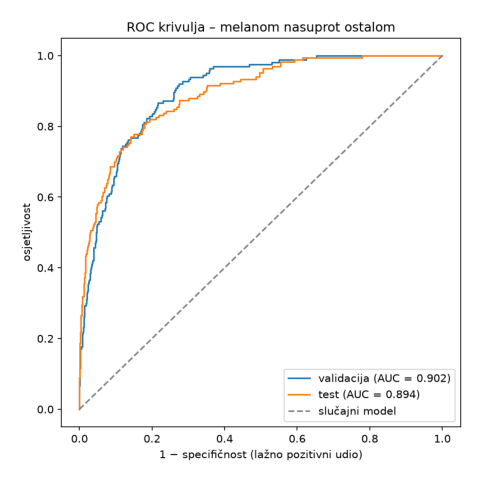

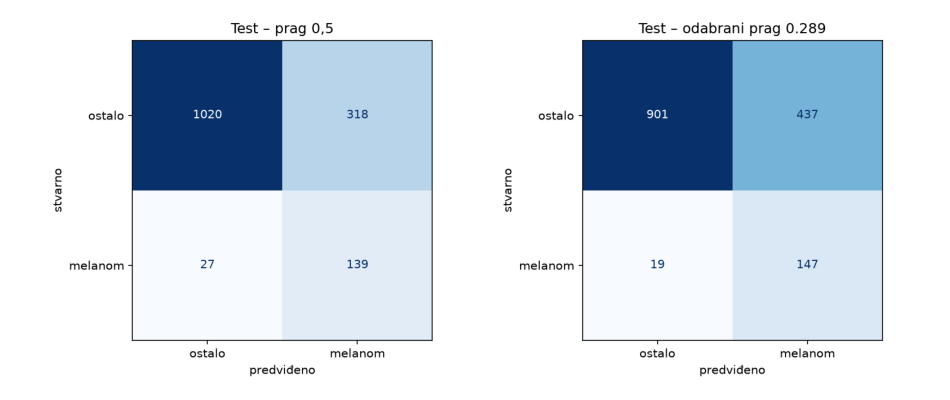

In [14]:
# Prikaz grafova evaluacije (spremljenih u rezultati/evaluacija)
for ime in ["roc_val_test.png", "matrice_zabune_test.png"]:   # za svaku sliku
    plt.figure(figsize=(12, 6))                                    # velika površina za prikaz
    plt.imshow(Image.open(REZ / "evaluacija" / ime))               # otvori i prikaži spremljeni graf
    plt.axis("off")                                                # bez osi
    plt.show()

## 7. Vanjska provjera na HIBA-i (druga bolnica, isti model i prag)

In [15]:
%%writefile evaluate_hiba.py
#
# Vanjska provjera generalizacije na HIBA (samo dermatoskopske slike)
# Isti model i ISTI prag kao za test (prag.json, izabran na HAM validaciji) – ništa se ne podešava na HIBA-i.
# Rezultati: ukupno, po tipu kože (Fitzpatrick), po dijagnozi; ROC HAM test nasuprot HIBA.
#
import json                                   # čitanje praga
from pathlib import Path                      # putanje

import matplotlib.pyplot as plt               # grafovi
import pandas as pd                           # tablice
import torch                                  # PyTorch
from PIL import Image                         # otvaranje slika
from torch.utils.data import Dataset, DataLoader   # vlastiti skup slika i batchevi
from sklearn.metrics import roc_curve, roc_auc_score   # ROC i AUC

# funkcije i postavke koje smo već napisali u evaluate_melanom.py (ista obrada i iste formule)
from evaluate_melanom import load_model, get_eval_transform, izracunaj_metrike, nacrtaj_matricu, MELANOM, PRAG_PATH


#
# GLOBALNE POSTAVKE
#
HIBA_DIR = Path("data") / "hiba"                                          # HIBA slike i tablica
HAM_TEST_PRED = Path("rezultati") / "evaluacija" / "predikcije_test.csv"  # HAM test – za usporedni ROC
REZ_DIR = Path("rezultati") / "hiba"                                      # kamo spremamo rezultate
BATCH_SIZE = 32
NUM_WORKERS = 4
SKUPINE_KOZE = {"I": "I–II", "II": "I–II", "III": "III–IV", "IV": "III–IV"}   # spajamo tipove kože u skupine


class HibaDataset(Dataset):
    # HIBA nije složena u mape po klasama, pa ImageFolder ne radi – vlastiti Dataset (DL20)
    def __init__(self, tablica, putanje, transform):
        self.tablica = tablica          # tablica s isic_id i oznakom
        self.putanje = putanje          # isic_id -> datoteka
        self.transform = transform      # obrada slike (kao na testu)

    def __len__(self):
        return len(self.tablica)        # broj slika u skupu

    def __getitem__(self, i):
        red = self.tablica.iloc[i]                                         # i-ti redak tablice
        slika = Image.open(self.putanje[red["isic_id"]]).convert("RGB")   # uvijek 3 kanala boje
        return self.transform(slika), int(red["oznaka"])                  # (obrađena slika, oznaka)


def ucitaj_hiba():
    hiba = pd.read_csv(HIBA_DIR / "metadata.csv")                              # HIBA tablica
    hiba = hiba[hiba["image_type"] == "dermoscopic"].reset_index(drop=True)   # samo dermatoskopske
    hiba["oznaka"] = (hiba["diagnosis"] == "melanoma").astype(int)           # 1 = melanom
    hiba["skupina_koze"] = hiba["fitzpatrick_skin_type"].map(SKUPINE_KOZE).fillna("nema podatka")   # I–II / III–IV / nema podatka
    return hiba


@torch.no_grad()                                                              # bez računanja gradijenata
def predict_hiba(model, hiba, device):
    putanje = {p.stem: p for p in HIBA_DIR.rglob("*.jpg")}                    # kazalo: isic_id -> putanja
    ds = HibaDataset(hiba, putanje, get_eval_transform())                     # skup slika
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)   # stalan redoslijed

    vjerojatnosti = []
    for x, _ in loader:                                                       # batch po batch
        logits = model(x.to(device))                                          # 2 broja po slici
        vjerojatnosti.extend(torch.softmax(logits, dim=1)[:, MELANOM].cpu().tolist())   # skor za melanom

    hiba["p_melanom"] = vjerojatnosti                                         # dopiši skor u tablicu
    return hiba


def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")    # GPU ili CPU
    REZ_DIR.mkdir(parents=True, exist_ok=True)                               # mapa za rezultate

    with open(PRAG_PATH, encoding="utf-8") as f:
        prag = json.load(f)["prag"]                       # ZAKLJUČANI prag s HAM validacije
    print(f"Prag iz {PRAG_PATH}: {prag:.4f}")

    model = load_model(device)                                               # isti model kao za test
    hiba = predict_hiba(model, ucitaj_hiba(), device)                        # skorovi za sve HIBA slike
    hiba["odluka"] = (hiba["p_melanom"] >= prag).astype(int)                 # odluka uz zaključani prag
    print(f"HIBA dermatoskopskih slika: {len(hiba)} | melanoma: {hiba['oznaka'].sum()}")

    # 1) Ukupno: prag 0,5 i zaključani prag
    redovi = []
    for p in [0.5, prag]:                                                    # oba praga
        m = izracunaj_metrike(hiba, p)                                       # iste formule kao za HAM
        m["skup"] = "HIBA"
        redovi.append(m)
    ukupno = pd.DataFrame(redovi)
    print("\nUKUPNO:\n" + ukupno.to_string(index=False))
    ukupno.to_csv(REZ_DIR / "metrike_hiba.csv", index=False)

    # 2) Po tipu kože (zaključani prag)
    redovi = []
    for skupina in ["I–II", "III–IV", "nema podatka"]:                       # svaka skupina kože
        dio = hiba[hiba["skupina_koze"] == skupina]                          # samo slike te skupine
        tp = ((dio["odluka"] == 1) & (dio["oznaka"] == 1)).sum()             # pronađeni melanomi
        fn = ((dio["odluka"] == 0) & (dio["oznaka"] == 1)).sum()             # propušteni melanomi
        tn = ((dio["odluka"] == 0) & (dio["oznaka"] == 0)).sum()             # točno "ostalo"
        fp = ((dio["odluka"] == 1) & (dio["oznaka"] == 0)).sum()             # lažne uzbune
        redovi.append({"skupina_koze": skupina, "slike": len(dio), "melanomi": int(tp + fn),
                       "TP": int(tp), "FN": int(fn),
                       "osjetljivost": round(tp / (tp + fn), 3),
                       "specificnost": round(tn / (tn + fp), 3)})
    po_kozi = pd.DataFrame(redovi)
    print("\nPO TIPU KOŽE (zaključani prag):\n" + po_kozi.to_string(index=False))
    po_kozi.to_csv(REZ_DIR / "hiba_po_tipu_koze.csv", index=False)

    # 3) Po dijagnozi: koliko slika je model označio kao melanom (1) ili ostalo (0)
    po_dijagnozi = pd.crosstab(hiba["diagnosis"], hiba["odluka"], margins=True, margins_name="ukupno")
    print("\nPO DIJAGNOZI (0 = ostalo, 1 = model kaže melanom):\n", po_dijagnozi)
    po_dijagnozi.to_csv(REZ_DIR / "hiba_po_dijagnozi.csv")

    # 4) ROC: HAM test nasuprot HIBA
    ham_test = pd.read_csv(HAM_TEST_PRED)                                    # spremljene HAM predikcije
    plt.figure(figsize=(6, 6))
    for ime, df in [("HAM10000 test", ham_test), ("HIBA (vanjski)", hiba)]:
        fpr, tpr, _ = roc_curve(df["oznaka"], df["p_melanom"])               # točke krivulje
        auc = roc_auc_score(df["oznaka"], df["p_melanom"])                   # AUC
        plt.plot(fpr, tpr, label=f"{ime} (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="slučajni model")
    plt.xlabel("1 − specifičnost")
    plt.ylabel("osjetljivost")
    plt.title("ROC – HAM10000 test i vanjska provjera HIBA")
    plt.legend()
    plt.tight_layout()
    plt.savefig(REZ_DIR / "roc_ham_hiba.png", dpi=150)
    plt.close()

    # 5) Matrica zabune HIBA (zaključani prag)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    nacrtaj_matricu(hiba, prag, f"HIBA – prag {prag:.3f}", ax)
    plt.tight_layout()
    plt.savefig(REZ_DIR / "matrica_zabune_hiba.png", dpi=150)
    plt.close()

    # 6) Predikcije po slici (za prilagodbu praga i analizu pogrešaka)
    hiba[["isic_id", "lesion_id", "patient_id", "diagnosis", "fitzpatrick_skin_type", "skupina_koze",
          "oznaka", "p_melanom", "odluka"]].to_csv(REZ_DIR / "predikcije_hiba.csv", index=False)
    print(f"\nSpremljeno u {REZ_DIR}")


if __name__ == "__main__":     # pokreće se samo kad skriptu pokrenemo izravno
    main()

Overwriting evaluate_hiba.py


In [16]:
# pokreni vanjsku provjeru na HIBA-i (isti model, isti prag)
!python evaluate_hiba.py

Prag iz rezultati\evaluacija\prag.json: 0.2894
Učitan model iz epohe 6 (val_AUC=0.9017)
HIBA dermatoskopskih slika: 1280 | melanoma: 196

UKUPNO:
  prag  TP  FN  TN  FP  osjetljivost  specificnost  preciznost     F1  balanced_acc  tocnost    AUC skup
0.5000 118  78 932 152        0.6020        0.8598      0.4370 0.5064        0.7309   0.8203 0.8232 HIBA
0.2894 141  55 834 250        0.7194        0.7694      0.3606 0.4804        0.7444   0.7617 0.8232 HIBA

PO TIPU KOŽE (zaključani prag):
skupina_koze  slike  melanomi  TP  FN  osjetljivost  specificnost
        I–II    901       169 125  44         0.740         0.701
      III–IV    271        17  11   6         0.647         0.906
nema podatka    108        10   5   5         0.500         0.929

PO DIJAGNOZI (0 = ostalo, 1 = model kaže melanom):
 odluka                     0    1  ukupno
diagnosis                                
actinic keratosis         37    9      46
basal cell carcinoma     151   79     230
dermatofibroma       

In [17]:
# ===== 7b. Lokalna prilagodba praga odluke na HIBA-i =====
# Pitanje: može li nova bolnica vratiti osjetljivost samo pomakom praga, bez ponovnog treniranja?
from sklearn.model_selection import train_test_split                     # podjela na dvije polovice
from evaluate_melanom import odaberi_prag, izracunaj_metrike      # ista pravila i formule kao za HAM

pred_hiba = pd.read_csv(REZ / "hiba" / "predikcije_hiba.csv")            # spremljeni HIBA skorovi
with open(REZ / "evaluacija" / "prag.json", encoding="utf-8") as f:
    prag_ham = json.load(f)["prag"]                                       # zaključani prag s HAM validacije

# 1) tablica PACIJENATA: 1 ako pacijent ima barem jedan melanom
pacijenti = pred_hiba.groupby("patient_id")["oznaka"].max().reset_index()

# 2) pacijente dijelimo na pola (polovica za odabir praga / polovica za provjeru), stratificirano po melanomu
kal_pac, prov_pac = train_test_split(pacijenti, test_size=0.5,
                                     stratify=pacijenti["oznaka"], random_state=SEED)
kal = pred_hiba[pred_hiba["patient_id"].isin(kal_pac["patient_id"])]      # polovica za odabir praga
prov = pred_hiba[pred_hiba["patient_id"].isin(prov_pac["patient_id"])]    # provjerna polovica
print(f"Kalibracija: {len(kal_pac)} pacijenata, {len(kal)} slika, {kal['oznaka'].sum()} melanoma")
print(f"Provjera   : {len(prov_pac)} pacijenata, {len(prov)} slika, {prov['oznaka'].sum()} melanoma")

# 3) lokalni prag – ISTO pravilo kao na HAM validaciji (osjetljivost >= 95 %), samo na prvoj polovici
prag_lokalni = odaberi_prag(kal)
print(f"\nPrag s HAM validacije: {prag_ham:.4f} | lokalni prag (HIBA kalibracija): {prag_lokalni:.4f}")

# 4) usporedba na provjernoj polovici
redovi = []
for ime, p in [("HAM prag", prag_ham), ("lokalni prag", prag_lokalni)]:  # oba praga na istim pacijentima
    m = izracunaj_metrike(prov, p)                                        # sve metrike
    m["prag_izvor"] = ime                                                 # koji je prag
    redovi.append(m)
usporedba = pd.DataFrame(redovi)

stupci = ["prag_izvor", "prag", "TP", "FN", "TN", "FP",
          "osjetljivost", "specificnost", "preciznost"]                    # stupci za ispis
print("\nProvjerna polovica HIBA-e:")
print(usporedba[stupci].to_string(index=False))

usporedba.to_csv(REZ / "hiba" / "lokalna_kalibracija.csv", index=False)  # spremi (staro ime datoteke ostaje)

Kalibracija: 294 pacijenata, 648 slika, 101 melanoma
Provjera   : 295 pacijenata, 632 slika, 95 melanoma

Prag s HAM validacije: 0.2894 | lokalni prag (HIBA kalibracija): 0.0673

Provjerna polovica HIBA-e:
  prag_izvor   prag  TP  FN  TN  FP  osjetljivost  specificnost  preciznost
    HAM prag 0.2894  70  25 408 129        0.7368        0.7598      0.3518
lokalni prag 0.0673  88   7 269 268        0.9263        0.5009      0.2472


## 8. Analiza pogrešaka

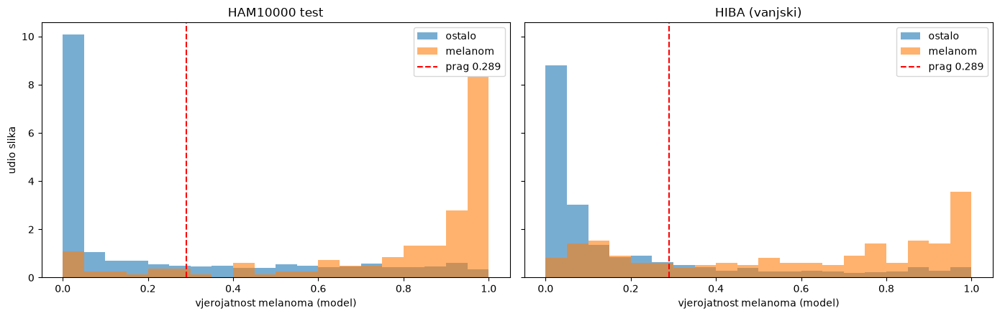

HAM10000 test: medijan vjerojatnosti – ostalo 0.046, melanom 0.929
HIBA: medijan vjerojatnosti – ostalo 0.063, melanom 0.65

Nevusi u testu – način potvrde × odluka (0 = ostalo, 1 = model kaže melanom):
odluka       0    1  ukupno
dx_type                    
consensus   32   55      87
follow_up  572    4     576
histo      113  227     340
ukupno     717  286    1003


In [18]:
# ===== 8a. Raspodjela skora (HAM test i HIBA) i nevusi po načinu potvrde =====
ANALIZA_DIR = REZ / "analiza_pogresaka"                                   # mapa za analizu pogrešaka
ANALIZA_DIR.mkdir(parents=True, exist_ok=True)                            # napravi ako ne postoji

pred_test = pd.read_csv(REZ / "evaluacija" / "predikcije_test.csv")      # spremljeni HAM test skorovi
pred_test["image_id"] = [Path(p).stem for p in pred_test["putanja"]]     # ime slike iz putanje (bez .jpg)
podjela = pd.read_csv(REZ / "podjela_ham.csv")                            # popis podjele s dijagnozama
pred_test = pred_test.merge(podjela[["image_id", "dx", "dx_type"]], on="image_id")   # dodaj dijagnozu i potvrdu
pred_test["dg"] = pred_test["dx"]                                         # zajednički naziv stupca za dijagnozu
pred_hiba["dg"] = pred_hiba["diagnosis"]                                  # isto za HIBA

# histogram vjerojatnosti melanoma po klasi, s pragom
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)            # dva grafa, ista y-os
for ax, (ime, df) in zip(axes, [("HAM10000 test", pred_test), ("HIBA (vanjski)", pred_hiba)]):
    ax.hist(df[df["oznaka"] == 0]["p_melanom"], bins=20, range=(0, 1), alpha=0.6, density=True, label="ostalo")    # skor – ostalo
    ax.hist(df[df["oznaka"] == 1]["p_melanom"], bins=20, range=(0, 1), alpha=0.6, density=True, label="melanom")   # skor – melanom
    ax.axvline(prag_ham, color="red", linestyle="--", label=f"prag {prag_ham:.3f}")   # crta praga
    ax.set_title(ime)
    ax.set_xlabel("vjerojatnost melanoma (model)")
    ax.legend()
axes[0].set_ylabel("udio slika")
plt.tight_layout()
plt.savefig(ANALIZA_DIR / "raspodjela_vjerojatnosti.png", dpi=150)       # spremi
plt.show()

for ime, df in [("HAM10000 test", pred_test), ("HIBA", pred_hiba)]:
    medijani = df.groupby("oznaka")["p_melanom"].median().round(3)       # medijan skora po klasi
    print(f"{ime}: medijan vjerojatnosti – ostalo {medijani[0]}, melanom {medijani[1]}")

# nevusi u HAM testu: način potvrde × odluka modela
nevusi = pred_test[pred_test["dx"] == "nv"]                               # samo nevusi
print("\nNevusi u testu – način potvrde × odluka (0 = ostalo, 1 = model kaže melanom):")
print(pd.crosstab(nevusi["dx_type"], nevusi["odluka"], margins=True, margins_name="ukupno"))

HAM10000 test: propuštenih melanoma 19, lažnih uzbuna 437


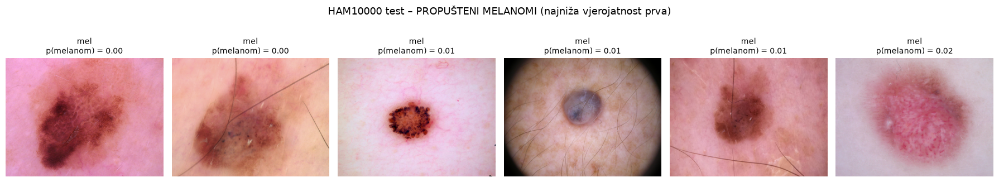

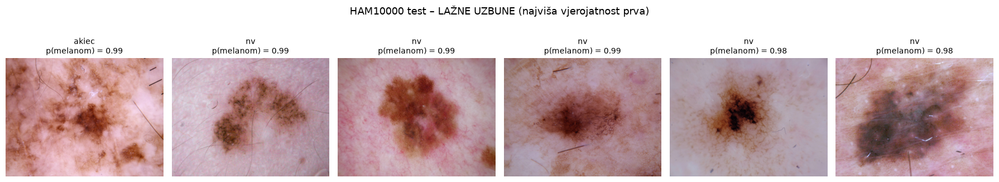

HIBA: propuštenih melanoma 55, lažnih uzbuna 250


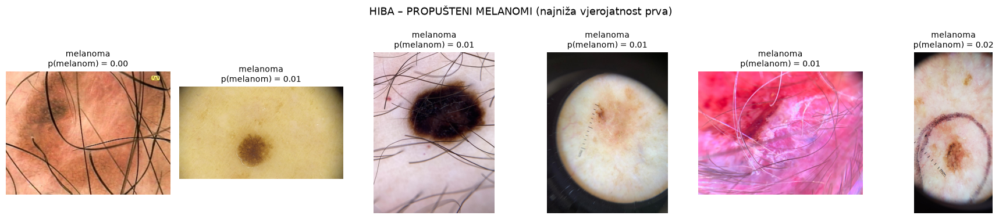

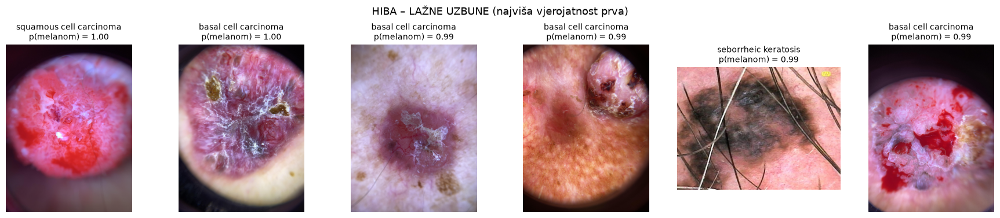

In [19]:
# ===== 8b. Primjeri pogrešaka – propušteni melanomi i lažne uzbune =====
hiba_putanje = {p.stem: p for p in HIBA_DIR.rglob("*.jpg")}              # kazalo: isic_id -> putanja
pred_hiba["putanja"] = pred_hiba["isic_id"].map(hiba_putanje)             # dopiši putanju svakoj HIBA slici


def prikazi_mrezu(df, naslov, datoteka, n=6):
    # prikaže prvih n slika iz tablice, s dijagnozom i vjerojatnošću melanoma
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.8))                  # n slika u redu
    for ax, (_, red) in zip(axes, df.head(n).iterrows()):                 # prvih n redaka
        ax.imshow(Image.open(red["putanja"]))                             # prikaži sliku
        ax.set_title(f'{red["dg"]}\np(melanom) = {red["p_melanom"]:.2f}', fontsize=10)   # dijagnoza i skor
    for ax in axes:
        ax.axis("off")                                                    # bez osi
    plt.suptitle(naslov, fontsize=13)
    plt.tight_layout()
    plt.savefig(ANALIZA_DIR / datoteka, dpi=150)                          # spremi
    plt.show()


for ime, df, kratko in [("HAM10000 test", pred_test, "test"), ("HIBA", pred_hiba, "hiba")]:
    fn = df[(df["oznaka"] == 1) & (df["odluka"] == 0)].sort_values("p_melanom")                    # propušteni melanomi
    fp = df[(df["oznaka"] == 0) & (df["odluka"] == 1)].sort_values("p_melanom", ascending=False)   # lažne uzbune
    print(f"{ime}: propuštenih melanoma {len(fn)}, lažnih uzbuna {len(fp)}")
    prikazi_mrezu(fn, f"{ime} – PROPUŠTENI MELANOMI (najniža vjerojatnost prva)", f"fn_{kratko}.png")   # najgori promašaji
    prikazi_mrezu(fp, f"{ime} – LAŽNE UZBUNE (najviša vjerojatnost prva)", f"fp_{kratko}.png")         # najuvjerljivije lažne uzbune

## 9. Grad-CAM – gdje model gleda?

In [20]:
# instalacija biblioteke za Grad-CAM – potrebno samo prvi put (treba internet)
%pip install grad-cam

Note: you may need to restart the kernel to use updated packages.


Učitan model iz epohe 6 (val_AUC=0.9017)


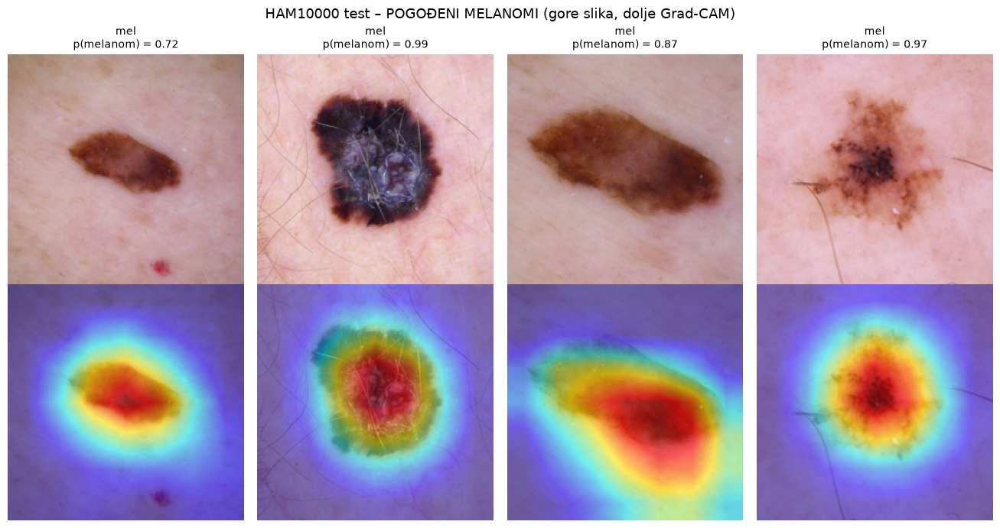

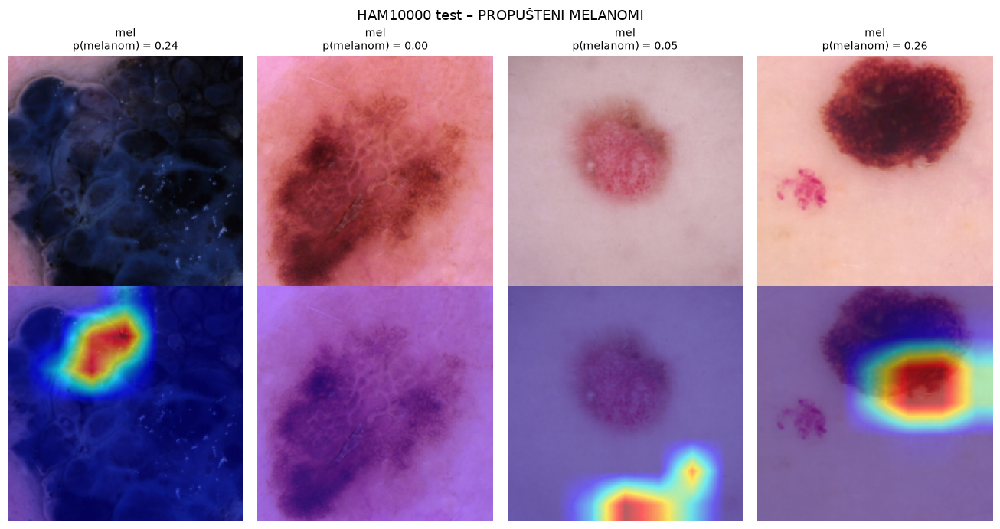

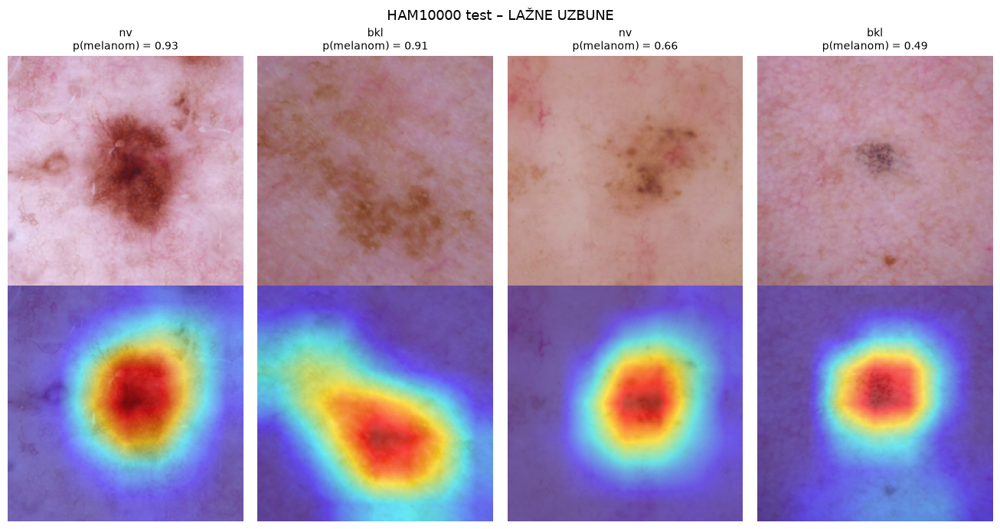

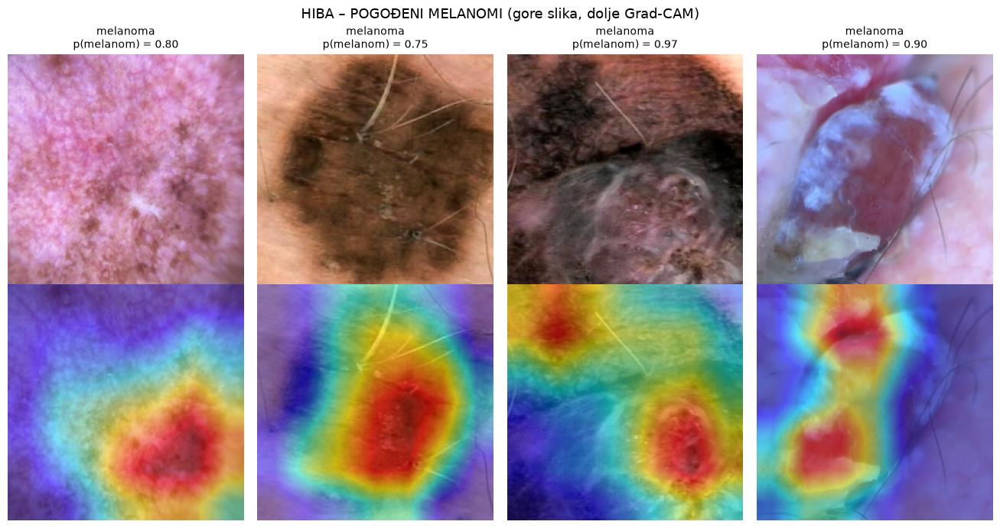

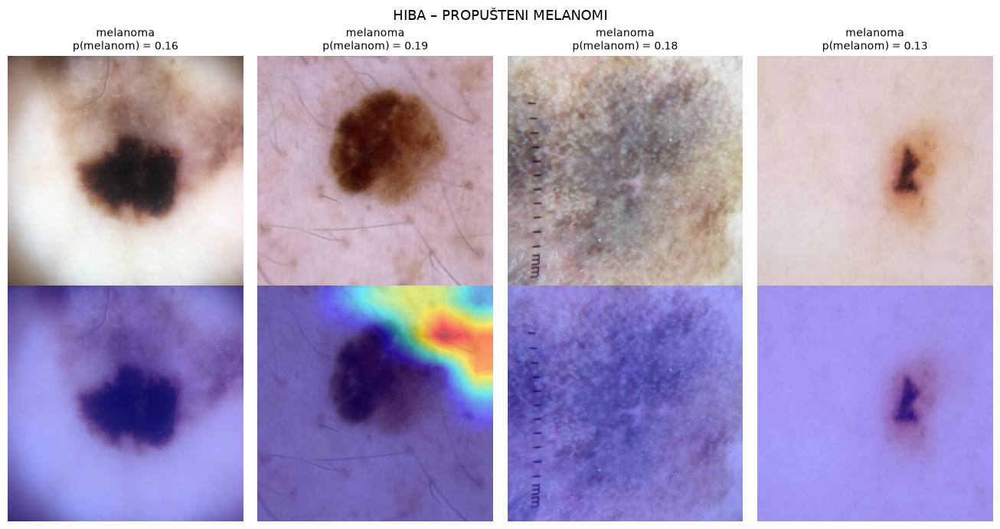

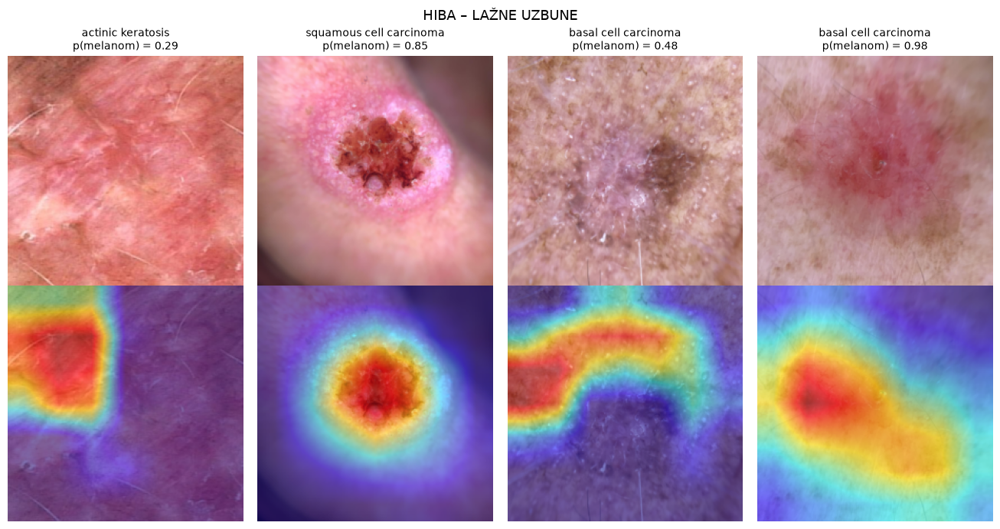

In [21]:
# ===== 9b. Grad-CAM – gdje model gleda? =====
from pytorch_grad_cam import GradCAM                                       # Grad-CAM metoda
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget    # za koju klasu tražimo kartu
from pytorch_grad_cam.utils.image import show_cam_on_image                 # karta preko slike
from torchvision import transforms                                         # izrez slike za prikaz
from evaluate_melanom import load_model, get_eval_transform, MELANOM       # naš model i obrada

gc_model = load_model(torch.device("cpu"))                              # najbolji model
gc_transform = get_eval_transform()                                     # ista obrada kao kod testa
izrez = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])   # isti izrez, bez normalizacije (za prikaz)

# Grad-CAM gleda zadnji konvolucijski blok ResNet-18 (layer4) – tamo su "najpametnije" značajke
cam = GradCAM(model=gc_model, target_layers=[gc_model.layer4[-1]])


def prikazi_gradcam(df, naslov, datoteka, n=4):
    primjeri = df.sample(min(n, len(df)), random_state=SEED)              # n nasumičnih primjera (seed 42)
    fig, axes = plt.subplots(2, n, figsize=(3.3 * n, 7))                  # gore slika, dolje karta
    for j, (_, red) in enumerate(primjeri.iterrows()):
        slika = Image.open(red["putanja"]).convert("RGB")                           # otvori sliku
        x = gc_transform(slika).unsqueeze(0)                                        # ulaz za model
        karta = cam(input_tensor=x, targets=[ClassifierOutputTarget(MELANOM)])[0]   # toplinska karta za "melanom"
        rgb = np.array(izrez(slika), dtype=np.float32) / 255                        # ista slika, vrijednosti 0–1
        preklop = show_cam_on_image(rgb, karta, use_rgb=True)                       # karta preko slike

        axes[0, j].imshow(rgb)                                                      # gore: slika
        axes[0, j].set_title(f'{red["dg"]}\np(melanom) = {red["p_melanom"]:.2f}', fontsize=10)
        axes[1, j].imshow(preklop)                                                  # dolje: slika s kartom
    for ax in axes.flatten():
        ax.axis("off")                                                    # bez osi
    plt.suptitle(naslov, fontsize=13)
    plt.tight_layout()
    plt.savefig(ANALIZA_DIR / datoteka, dpi=150)                          # spremi
    plt.show()


for ime, df, kratko in [("HAM10000 test", pred_test, "test"), ("HIBA", pred_hiba, "hiba")]:
    tp = df[(df["oznaka"] == 1) & (df["odluka"] == 1)]                    # pronađeni melanomi
    fn = df[(df["oznaka"] == 1) & (df["odluka"] == 0)]                    # propušteni melanomi
    fp = df[(df["oznaka"] == 0) & (df["odluka"] == 1)]                    # lažne uzbune
    prikazi_gradcam(tp, f"{ime} – POGOĐENI MELANOMI (gore slika, dolje Grad-CAM)", f"gradcam_tp_{kratko}.png")
    prikazi_gradcam(fn, f"{ime} – PROPUŠTENI MELANOMI", f"gradcam_fn_{kratko}.png")
    prikazi_gradcam(fp, f"{ime} – LAŽNE UZBUNE", f"gradcam_fp_{kratko}.png")

## 10. BCN20000 – završni neovisni test (Barcelona)

In [22]:
# ===== 10a. BCN20000 – prvi pregled tablice (samo metapodaci, bez modela) =====
bcn_csv = list(BCN_DIR.glob("*.csv"))[0]           # bcn20000_metadata_....csv
bcn = pd.read_csv(bcn_csv)                          # učitaj tablicu
print("Datoteka:", bcn_csv.name)                    # ime datoteke
print("Oblik tablice:", bcn.shape)                  # broj redaka i stupaca
print("\nStupci:", list(bcn.columns))               # imena stupaca
print("\nNedostajuće vrijednosti:\n", bcn.isnull().sum())   # prazna polja po stupcu

for stupac in bcn.columns:                         # za svaki stupac
    if bcn[stupac].nunique() <= 15:                # samo stupci-kategorije
        print(f"\n--- {stupac} ---")
        print(bcn[stupac].value_counts(dropna=False))   # koliko je kojih vrijednosti

print("\nBroj .jpg slika u mapi:", len(list(BCN_DIR.rglob("*.jpg"))))   # slike na disku

Datoteka: bcn20000_metadata_2026-11-02.csv
Oblik tablice: (18946, 16)

Stupci: ['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_1', 'anatom_site_2', 'anatom_site_special', 'concomitant_biopsy', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_confirm_type', 'image_type', 'lesion_id', 'melanocytic', 'sex']

Nedostajuće vrijednosti:
 isic_id                       0
attribution                   0
copyright_license             0
age_approx                  121
anatom_site_1              1066
anatom_site_2             11577
anatom_site_special       18177
concomitant_biopsy            0
diagnosis_1                1156
diagnosis_2                1156
diagnosis_3                1307
diagnosis_confirm_type     3506
image_type                    0
lesion_id                     0
melanocytic                1156
sex                         117
dtype: int64

--- attribution ---
attribution
Hospital Clínic de Barcelona    18946
Name: count, dtype: int64

--- copyri

In [24]:
# ===== 10b. BCN20000 – isključenja, jedna slika po leziji, pregled =====
print("Sve slike:", len(bcn))                                             # broj svih slika

# 1) isključenja (prema planu)
bez_dijagnoze = bcn["diagnosis_1"].isnull()                               # slike bez dijagnoze
metastaza = bcn["diagnosis_3"] == "Melanoma metastasis"                   # metastaze melanoma (nisu primarna lezija)
print("Isključeno – bez dijagnoze:", bez_dijagnoze.sum(), "| metastaze melanoma:", metastaza.sum())
bcn_ok = bcn[~bez_dijagnoze & ~metastaza].copy()                          # zadrži sve ostale

# 2) oznaka melanoma i čitljiva dijagnoza (diagnosis_3, a gdje je prazna -> diagnosis_2)
bcn_ok["oznaka"] = (bcn_ok["diagnosis_3"] == "Melanoma, NOS").astype(int)  # 1 = melanom
bcn_ok["dg"] = bcn_ok["diagnosis_3"].fillna(bcn_ok["diagnosis_2"])         # naziv dijagnoze
print("Nakon isključenja:", len(bcn_ok), "slika |", bcn_ok["lesion_id"].nunique(), "lezija")

# 3) slike po leziji
slika_po_leziji = bcn_ok.groupby("lesion_id")["isic_id"].count()          # broj slika svake lezije
mel_lezije = bcn_ok[bcn_ok["oznaka"] == 1]["lesion_id"].unique()          # lezije koje su melanom
print(f"Prosječno slika po leziji: svi {slika_po_leziji.mean():.2f}, melanomi {slika_po_leziji[mel_lezije].mean():.2f}")

# 4) jedna slika po leziji (prva) -> to je naš BCN test
bcn_test = bcn_ok.drop_duplicates(subset="lesion_id").reset_index(drop=True)   # prva slika svake lezije
print("\nBCN TEST (jedna slika po leziji):", len(bcn_test), "lezija")
print("Melanom (1) / ostalo (0):\n", bcn_test["oznaka"].value_counts())
print("\nDijagnoze:\n", bcn_test["dg"].value_counts())
print("\nPotvrda dijagnoze kod melanoma:\n",
      bcn_test[bcn_test["oznaka"] == 1]["diagnosis_confirm_type"].value_counts(dropna=False))

# 5) veličine slika (na odabranim slikama)
bcn_putanje = {p.stem: p for p in BCN_DIR.rglob("*.jpg")}                 # kazalo: isic_id -> putanja
velicine = pd.Series([Image.open(bcn_putanje[i]).size for i in bcn_test["isic_id"]])   # (širina, visina)
print("\nNajčešće veličine slika:\n", velicine.value_counts().head(5))

# 6) spremi popis za evaluaciju
bcn_test[["isic_id", "lesion_id", "dg", "diagnosis_confirm_type", "oznaka"]].to_csv(EDA_DIR / "bcn_test_popis.csv", index=False)
print("\nPopis spremljen:", EDA_DIR / "bcn_test_popis.csv")

Sve slike: 18946
Isključeno – bez dijagnoze: 1156 | metastaze melanoma: 633
Nakon isključenja: 17157 slika | 4848 lezija
Prosječno slika po leziji: svi 3.54, melanomi 5.76

BCN TEST (jedna slika po leziji): 4848 lezija
Melanom (1) / ostalo (0):
 oznaka
0    4153
1     695
Name: count, dtype: int64

Dijagnoze:
 dg
Nevus                                           1704
Basal cell carcinoma                            1305
Melanoma, NOS                                    695
Seborrheic keratosis                             392
Solar or actinic keratosis                       314
Squamous cell carcinoma, NOS                     161
Scar                                              96
Solar lentigo                                     79
Dermatofibroma                                    54
Benign soft tissue proliferations - Vascular      48
Name: count, dtype: int64

Potvrda dijagnoze kod melanoma:
 diagnosis_confirm_type
histopathology    695
Name: count, dtype: int64

Najčešće veličine slika

In [25]:
%%writefile evaluate_bcn.py
#
# ZAVRŠNI NEOVISNI TEST na BCN20000 (Barcelona) – skup koji nikad prije nije gledan
# Isti model i ISTI prag (prag.json, izabran na HAM validaciji). Jedna slika po leziji (popis iz bilježnice).
#
import json                                   # čitanje praga
from pathlib import Path                      # putanje

import matplotlib.pyplot as plt               # grafovi
import pandas as pd                           # tablice
import torch                                  # PyTorch
from torch.utils.data import DataLoader       # batchevi slika
from sklearn.metrics import roc_curve, roc_auc_score   # ROC i AUC

from evaluate_melanom import load_model, get_eval_transform, izracunaj_metrike, nacrtaj_matricu, MELANOM, PRAG_PATH
from evaluate_hiba import HibaDataset      # isti Dataset: radi za svaku tablicu sa stupcima isic_id i oznaka


#
# GLOBALNE POSTAVKE
#
BCN_DIR = Path("data") / "bcn20000"                                        # BCN slike
BCN_POPIS = Path("rezultati") / "eda" / "bcn_test_popis.csv"               # popis iz ćelije 10b
HAM_TEST_PRED = Path("rezultati") / "evaluacija" / "predikcije_test.csv"   # za usporedni ROC
HIBA_PRED = Path("rezultati") / "hiba" / "predikcije_hiba.csv"             # za usporedni ROC
REZ_DIR = Path("rezultati") / "bcn"                                        # kamo spremamo rezultate
BATCH_SIZE = 32
NUM_WORKERS = 4


@torch.no_grad()                                                           # bez računanja gradijenata
def predict_bcn(model, bcn, device):
    putanje = {p.stem: p for p in BCN_DIR.rglob("*.jpg")}                  # kazalo: isic_id -> putanja
    ds = HibaDataset(bcn, putanje, get_eval_transform())                   # skup slika
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

    vjerojatnosti = []
    for x, _ in loader:                                                    # batch po batch
        logits = model(x.to(device))                                       # 2 broja po slici
        vjerojatnosti.extend(torch.softmax(logits, dim=1)[:, MELANOM].cpu().tolist())   # skor za melanom

    bcn["p_melanom"] = vjerojatnosti                                       # dopiši skor u tablicu
    return bcn


def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    REZ_DIR.mkdir(parents=True, exist_ok=True)

    with open(PRAG_PATH, encoding="utf-8") as f:
        prag = json.load(f)["prag"]                                        # ZAKLJUČANI prag s HAM validacije
    print(f"Prag iz {PRAG_PATH}: {prag:.4f}")

    model = load_model(device)                                             # isti model
    bcn = predict_bcn(model, pd.read_csv(BCN_POPIS), device)               # skorovi za sve BCN lezije
    bcn["odluka"] = (bcn["p_melanom"] >= prag).astype(int)                 # odluka uz zaključani prag
    print(f"BCN lezija: {len(bcn)} | melanoma: {bcn['oznaka'].sum()}")

    # 1) Ukupno: prag 0,5 i zaključani prag
    redovi = []
    for p in [0.5, prag]:
        m = izracunaj_metrike(bcn, p)                                      # iste formule kao za HAM
        m["skup"] = "BCN20000"
        redovi.append(m)
    ukupno = pd.DataFrame(redovi)
    print("\nUKUPNO:\n" + ukupno.to_string(index=False))
    ukupno.to_csv(REZ_DIR / "metrike_bcn.csv", index=False)

    # 2) Po dijagnozi
    po_dijagnozi = pd.crosstab(bcn["dg"], bcn["odluka"], margins=True, margins_name="ukupno")
    print("\nPO DIJAGNOZI (0 = ostalo, 1 = model kaže melanom):\n", po_dijagnozi)
    po_dijagnozi.to_csv(REZ_DIR / "bcn_po_dijagnozi.csv")

    # 3) ROC: sva tri skupa
    plt.figure(figsize=(6, 6))
    for ime, df in [("HAM10000 test", pd.read_csv(HAM_TEST_PRED)),
                    ("HIBA (Buenos Aires)", pd.read_csv(HIBA_PRED)),
                    ("BCN20000 (Barcelona)", bcn)]:
        fpr, tpr, _ = roc_curve(df["oznaka"], df["p_melanom"])            # točke krivulje
        auc = roc_auc_score(df["oznaka"], df["p_melanom"])                # AUC
        plt.plot(fpr, tpr, label=f"{ime} (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="slučajni model")
    plt.xlabel("1 − specifičnost")
    plt.ylabel("osjetljivost")
    plt.title("ROC – jedan model, tri bolnice")
    plt.legend()
    plt.tight_layout()
    plt.savefig(REZ_DIR / "roc_tri_skupa.png", dpi=150)
    plt.close()

    # 4) Matrica zabune BCN
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    nacrtaj_matricu(bcn, prag, f"BCN20000 – prag {prag:.3f}", ax)
    plt.tight_layout()
    plt.savefig(REZ_DIR / "matrica_zabune_bcn.png", dpi=150)
    plt.close()

    # 5) Predikcije po leziji
    bcn.to_csv(REZ_DIR / "predikcije_bcn.csv", index=False)               # spremi tablicu
    print(f"\nSpremljeno u {REZ_DIR}")


if __name__ == "__main__":     # pokreće se samo kad skriptu pokrenemo izravno
    main()

Overwriting evaluate_bcn.py


In [26]:
# pokreni završni neovisni test na BCN20000 (isti model, isti prag)
!python evaluate_bcn.py

Prag iz rezultati\evaluacija\prag.json: 0.2894
Učitan model iz epohe 6 (val_AUC=0.9017)
BCN lezija: 4848 | melanoma: 695

UKUPNO:
  prag  TP  FN   TN  FP  osjetljivost  specificnost  preciznost     F1  balanced_acc  tocnost    AUC     skup
0.5000 215 480 3905 248        0.3094        0.9403      0.4644 0.3713        0.6248   0.8498 0.7542 BCN20000
0.2894 305 390 3652 501        0.4388        0.8794      0.3784 0.4064        0.6591   0.8162 0.7542 BCN20000

PO DIJAGNOZI (0 = ostalo, 1 = model kaže melanom):
 odluka                                           0    1  ukupno
dg                                                             
Basal cell carcinoma                          1181  124    1305
Benign soft tissue proliferations - Vascular    43    5      48
Dermatofibroma                                  51    3      54
Melanoma, NOS                                  390  305     695
Nevus                                         1479  225    1704
Scar                                   

## 11. Demo – procjena pojedinačnih slika

Učitan model iz epohe 6 (val_AUC=0.9017)
Slike bez pronađene putanje – HIBA: 0 | BCN: 0
HAM  skor sada = 0.7230 | skor iz evaluacije = 0.7230
HAM  skor sada = 0.2414 | skor iz evaluacije = 0.2414
HIBA skor sada = 0.7977 | skor iz evaluacije = 0.7977
HIBA skor sada = 0.1640 | skor iz evaluacije = 0.1640
BCN  skor sada = 0.9764 | skor iz evaluacije = 0.9764
BCN  skor sada = 0.1168 | skor iz evaluacije = 0.1168


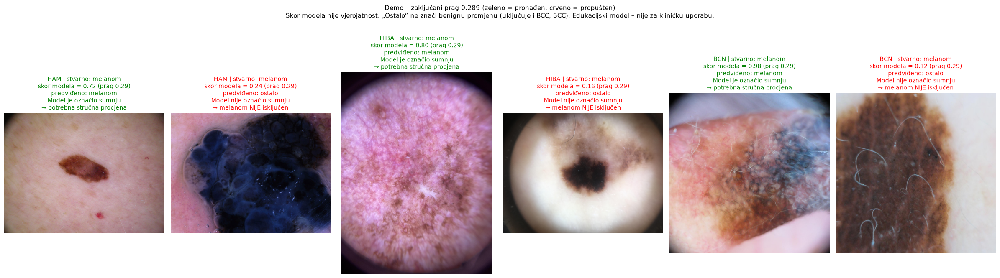

In [29]:
# =====================================================================
# 11. DEMO – procjena pojedinačnih slika
#     Radi bez interneta. Prije ove ćelije pokrenuti SAMO ćeliju 1.
# =====================================================================

# ---------------------------------------------------------------------
# 1) BIBLIOTEKE I POMOĆNE FUNKCIJE IZ NAŠE SKRIPTE
# ---------------------------------------------------------------------
import json                                   # čitanje zaključanog praga (prag.json)
import torch                                  # PyTorch – model
import pandas as pd                           # tablice s predikcijama
import matplotlib.pyplot as plt               # crtanje slika
from PIL import Image                         # otvaranje slika
from evaluate_melanom import load_model, get_eval_transform, MELANOM   # iz naše skripte

ANALIZA_DIR = REZ / "analiza_pogresaka"      # mapa u koju spremamo demo sliku
ANALIZA_DIR.mkdir(parents=True, exist_ok=True)   # napravi mapu ako ne postoji (npr. na drugom računalu)

# ---------------------------------------------------------------------
# 2) UČITAVANJE MODELA, TRANSFORMACIJE I ZAKLJUČANOG PRAGA
# ---------------------------------------------------------------------
demo_model = load_model(torch.device("cpu"))  # najbolji model (epoha 6), način rada eval
demo_transform = get_eval_transform()         # Resize(256) + CenterCrop(224) + Normalize – kao na testu

with open(REZ / "evaluacija" / "prag.json", encoding="utf-8") as f:
    prag = json.load(f)["prag"]               # prag 0,289 – odabran na validaciji, ne mijenja se


# ---------------------------------------------------------------------
# 3) FUNKCIJA: SKOR MODELA ZA JEDNU SLIKU
# ---------------------------------------------------------------------
def procijeni(putanja):
    # vrati sliku i skor modela za melanom za jednu sliku
    slika = Image.open(putanja).convert("RGB")           # otvori sliku, uvijek 3 kanala boje
    x = demo_transform(slika).unsqueeze(0)               # jedna slika -> batch od 1 slike
    with torch.no_grad():                                # samo predviđanje, bez učenja
        izlaz = demo_model(x)                            # dva broja (logiti): ostalo, melanom
        p = torch.softmax(izlaz, dim=1)[0, MELANOM].item()   # skor za melanom (0–1)
    return slika, p


# ---------------------------------------------------------------------
# 4) SPREMLJENE PREDIKCIJE I PUTANJE DO SLIKA
# ---------------------------------------------------------------------
pred_test = pd.read_csv(REZ / "evaluacija" / "predikcije_test.csv")   # HAM test (ima stupac putanja)
pred_hiba = pd.read_csv(REZ / "hiba" / "predikcije_hiba.csv")         # HIBA (ima isic_id)
pred_bcn  = pd.read_csv(REZ / "bcn" / "predikcije_bcn.csv")           # BCN (ima isic_id)

# „kazalo” slika: ISIC broj -> gdje je slika na disku
hiba_putanje = {p.stem: p for p in HIBA_DIR.rglob("*.jpg")}
bcn_putanje  = {p.stem: p for p in BCN_DIR.rglob("*.jpg")}
pred_hiba["putanja"] = pred_hiba["isic_id"].map(hiba_putanje)         # dopiši putanju svakom retku
pred_bcn["putanja"]  = pred_bcn["isic_id"].map(bcn_putanje)

# kontrola: mora biti 0 i 0 (sve slike pronađene)
print("Slike bez pronađene putanje – HIBA:", pred_hiba["putanja"].isna().sum(),
      "| BCN:", pred_bcn["putanja"].isna().sum())


# ---------------------------------------------------------------------
# 5) ODABIR SLIKA: po 1 pronađeni i 1 propušteni melanom iz svakog skupa
# ---------------------------------------------------------------------
demo = []
for izvor, df in [("HAM", pred_test), ("HIBA", pred_hiba), ("BCN", pred_bcn)]:
    pogodjen  = df[(df["oznaka"] == 1) & (df["odluka"] == 1)].sample(1, random_state=SEED)  # pravi melanom, model ga označio
    propusten = df[(df["oznaka"] == 1) & (df["odluka"] == 0)].sample(1, random_state=SEED)  # pravi melanom, model ga propustio
    for _, red in pd.concat([pogodjen, propusten]).iterrows():
        demo.append((izvor, red["putanja"], red["p_melanom"]))       # (skup, putanja, skor iz evaluacije)


# ---------------------------------------------------------------------
# 6) PRIKAZ: slika + skor + predviđena klasa + poruka
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, len(demo), figsize=(4 * len(demo), 6))  # 6 slika u jednom redu

for ax, (izvor, putanja, p_csv) in zip(axes, demo):
    slika, p = procijeni(putanja)                    # model ponovno procijeni sliku

    # odluka uz zaključani prag – poruke namjerno oprezne
    if p >= prag:
        klasa = "melanom"
        poruka = "Model je označio sumnju\n→ potrebna stručna procjena"
    else:
        klasa = "ostalo"
        poruka = "Model nije označio sumnju\n→ melanom NIJE isključen"

    ax.imshow(slika)                                 # prikaži sliku
    ax.set_title(f"{izvor} | stvarno: melanom\nskor modela = {p:.2f} (prag {prag:.2f})\n"
                 f"predviđeno: {klasa}\n{poruka}",
                 fontsize=10, color="green" if p >= prag else "red")   # zeleno = pronađen, crveno = propušten
    ax.axis("off")                                   # bez osi oko slike

    # kontrola: skor sada mora biti jednak skoru iz evaluacije
    print(f"{izvor:4} skor sada = {p:.4f} | skor iz evaluacije = {p_csv:.4f}")


# ---------------------------------------------------------------------
# 7) GLAVNI NASLOV, SPREMANJE I PRIKAZ
# ---------------------------------------------------------------------
plt.suptitle(f"Demo – zaključani prag {prag:.3f} (zeleno = pronađen, crveno = propušten)\n"
             "Skor modela nije vjerojatnost. „Ostalo” ne znači benignu promjenu (uključuje i BCC, SCC). "
             "Edukacijski model – nije za kliničku uporabu.",
             fontsize=11, y=1.10)                    # y=1.10 -> naslov iznad naslova slika
plt.tight_layout()
plt.savefig(ANALIZA_DIR / "demo.png", dpi=150, bbox_inches="tight")   # rezerva za obranu
plt.show()

## 12. requirements.txt

In [30]:
# ===== 12. requirements.txt – točne verzije paketa iz ovog okruženja =====
from importlib.metadata import version                  # čita verziju instaliranog paketa

paketi = ["torch", "torchvision", "scikit-learn", "pandas", "numpy",
          "matplotlib", "pillow", "tensorboard", "grad-cam"]       # paketi koje projekt koristi

with open("requirements.txt", "w", encoding="utf-8") as f:         # otvori datoteku za pisanje
    for paket in paketi:                                           # za svaki paket
        v = version(paket).split("+")[0]        # "2.14.1+cpu" -> "2.14.1"
        f.write(f"{paket}=={v}\n")                                 # zapiši npr. "torch==2.14.1"

print(open("requirements.txt", encoding="utf-8").read())           # ispiši sadržaj datoteke

torch==2.14.1
torchvision==0.29.1
scikit-learn==1.9.1
pandas==3.1.1
numpy==2.5.3
matplotlib==3.11.2
pillow==12.3.0
tensorboard==2.21.0
grad-cam==1.5.7



## 13. Dodatne analize (nakon recenzija)
Pokretati redom od 13b do 13h (13b učitava tablice koje koriste ostale ćelije). Prije toga pokrenuti ćeliju 1.

In [31]:
# ===== 13b. OBJEDINJENA TABLICA: jedan model, isti prag, tri skupa podataka =====
from sklearn.metrics import confusion_matrix, roc_auc_score              # matrica zabune i AUC

with open(REZ / "evaluacija" / "prag.json", encoding="utf-8") as f:
    PRAG = json.load(f)["prag"]                       # zaključani prag s validacije

def wilson(k, n, z=1.96):
    """95 % interval pouzdanosti za udio k od n (Wilsonova metoda)."""
    p = k / n                                                            # udio, npr. 147/166
    sredina = (p + z**2 / (2 * n)) / (1 + z**2 / n)                      # središte intervala
    pola = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)   # pola širine intervala
    return f"{sredina - pola:.3f}–{sredina + pola:.3f}"                  # npr. "0.828–0.925"

# učitaj spremljene predikcije
test = pd.read_csv(REZ / "evaluacija" / "predikcije_test.csv")          # HAM test
hiba = pd.read_csv(REZ / "hiba" / "predikcije_hiba.csv")                # HIBA
bcn  = pd.read_csv(REZ / "bcn" / "predikcije_bcn.csv")                  # BCN

# HAM test nema lesion_id -> dodaj ga iz popisa podjele (image_id = ime datoteke bez .jpg)
podjela = pd.read_csv(REZ / "podjela_ham.csv")                          # popis podjele
test["image_id"] = test["putanja"].apply(lambda p: Path(p).stem)        # ime slike iz putanje
test = test.merge(podjela[["image_id", "lesion_id"]], on="image_id")    # dopiši lesion_id

# popis skupova: (ime, tablica, jedinica evaluacije)
skupovi = [("HAM10000 test", test, "slika"),
           ("HIBA", hiba, "slika")]
for skupina in sorted(hiba["skupina_koze"].unique()):                   # HIBA po tipu kože
    skupovi.append(("HIBA – koža " + skupina, hiba[hiba["skupina_koze"] == skupina], "slika"))
skupovi.append(("BCN20000", bcn, "lezija (1 slika)"))

redovi = []
for ime, df, jedinica in skupovi:                                        # za svaki skup
    tn, fp, fn, tp = confusion_matrix(df["oznaka"], df["odluka"], labels=[0, 1]).ravel()   # uz zaključani prag
    redovi.append({
        "skup": ime,
        "jedinica": jedinica,
        "slika": len(df),                                                # broj slika
        "lezija": df["lesion_id"].nunique(),                             # broj lezija
        "pacijenata": df["patient_id"].nunique() if "patient_id" in df.columns else "nema podatka",   # samo HIBA ima pacijente
        "melanoma": tp + fn,                                             # svi pravi melanomi
        "AUC": round(roc_auc_score(df["oznaka"], df["p_melanom"]), 3),
        "osjetljivost": round(tp / (tp + fn), 3),
        "osj. 95 % CI": wilson(tp, tp + fn),                             # interval pouzdanosti osjetljivosti
        "specifičnost": round(tn / (tn + fp), 3),
        "spec. 95 % CI": wilson(tn, tn + fp),                            # interval pouzdanosti specifičnosti
        "preciznost": round(tp / (tp + fp), 3),
        "F1": round(2 * tp / (2 * tp + fp + fn), 3),
        "TP": tp, "FN": fn, "TN": tn, "FP": fp,
        "upućivanja po melanomu": round((tp + fp) / tp, 1),              # uputnica po 1 pronađenom melanomu
    })

tablica = pd.DataFrame(redovi)                                           # popis -> tablica
tablica.to_csv(REZ / "objedinjena_tablica.csv", index=False, encoding="utf-8-sig")   # spremi (čitljivo u Excelu)
print("Zaključani prag:", round(PRAG, 4), "| spremljeno: rezultati/objedinjena_tablica.csv")
tablica.set_index("skup").T          # okrenuto: skupovi su stupci, lakše se čita

Zaključani prag: 0.2894 | spremljeno: rezultati/objedinjena_tablica.csv


skup,HAM10000 test,HIBA,HIBA – koža III–IV,HIBA – koža I–II,HIBA – koža nema podatka,BCN20000
jedinica,slika,slika,slika,slika,slika,lezija (1 slika)
slika,1504,1280,271,901,108,4848
lezija,1121,1201,267,827,107,4848
pacijenata,nema podatka,589,70,462,57,nema podatka
melanoma,166,196,17,169,10,695
AUC,0.894,0.823,0.895,0.79,0.885,0.754
osjetljivost,0.886,0.719,0.647,0.74,0.5,0.439
osj. 95 % CI,0.828–0.925,0.653–0.778,0.413–0.827,0.669–0.800,0.237–0.763,0.402–0.476
specifičnost,0.673,0.769,0.906,0.701,0.929,0.879
spec. 95 % CI,0.648–0.698,0.743–0.793,0.863–0.936,0.667–0.733,0.860–0.965,0.869–0.889


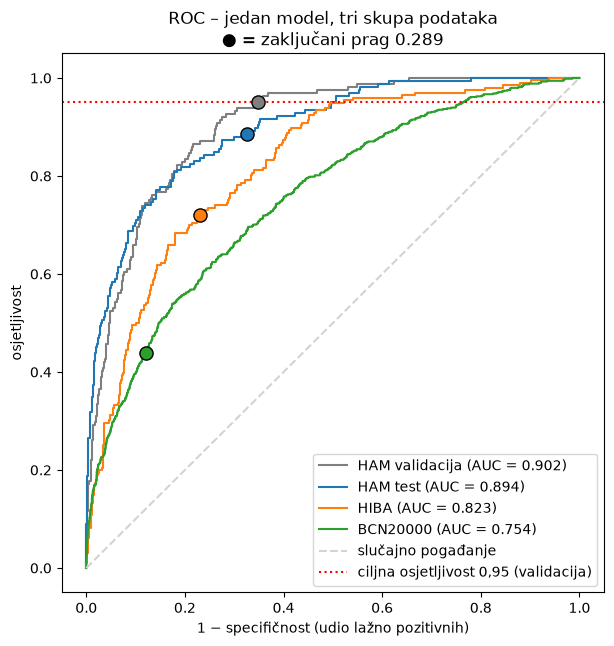

In [32]:
# ===== 13c. ROC KRIVULJE S OZNAČENOM RADNOM TOČKOM (zaključani prag) =====
from sklearn.metrics import roc_curve                                    # točke ROC krivulje

val = pd.read_csv(REZ / "evaluacija" / "predikcije_val.csv")            # HAM validacija

fig, ax = plt.subplots(figsize=(7, 7))
for ime, df, boja in [("HAM validacija", val, "tab:gray"),
                      ("HAM test", test, "tab:blue"),
                      ("HIBA", hiba, "tab:orange"),
                      ("BCN20000", bcn, "tab:green")]:                    # četiri skupa, svaki svoja boja
    fpr, tpr, _ = roc_curve(df["oznaka"], df["p_melanom"])           # cijela krivulja
    auc = roc_auc_score(df["oznaka"], df["p_melanom"])                   # AUC
    ax.plot(fpr, tpr, color=boja, label=f"{ime} (AUC = {auc:.3f})")      # nacrtaj krivulju
    # radna točka = gdje model stvarno radi uz zaključani prag
    tn, fp, fn, tp = confusion_matrix(df["oznaka"], df["odluka"], labels=[0, 1]).ravel()
    ax.scatter(fp / (fp + tn), tp / (tp + fn), s=90, color=boja, edgecolor="black", zorder=3)   # točka na krivulji

ax.plot([0, 1], [0, 1], "--", color="lightgray", label="slučajno pogađanje")                  # dijagonala
ax.axhline(0.95, linestyle=":", color="red", label="ciljna osjetljivost 0,95 (validacija)")    # cilj
ax.set_xlabel("1 − specifičnost (udio lažno pozitivnih)")
ax.set_ylabel("osjetljivost")
ax.set_title(f"ROC – jedan model, tri skupa podataka\n● = zaključani prag {PRAG:.3f}")
ax.legend(loc="lower right")
plt.savefig(REZ / "roc_radna_tocka.png", dpi=150, bbox_inches="tight")  # spremi za prezentaciju
plt.show()

In [33]:
# ===== 13d. REZULTATI PO LEZIJI: prosjek skora svih slika iste lezije, isti zaključani prag =====
redovi_lezija = []
for ime, df in [("HAM10000 test", test), ("HIBA", hiba)]:                # BCN već ima 1 sliku po leziji
    # jedna lezija = jedan redak; skor = prosjek skorova njezinih slika
    lez = df.groupby(["lesion_id", "oznaka"])["p_melanom"].mean().reset_index()
    print(ime, "| lezija:", lez["lesion_id"].nunique(), "| redaka:", len(lez))  # moraju biti jednaki

    lez["odluka"] = (lez["p_melanom"] >= PRAG).astype(int)       # isti prag kao za slike
    tn, fp, fn, tp = confusion_matrix(lez["oznaka"], lez["odluka"], labels=[0, 1]).ravel()   # matrica zabune
    redovi_lezija.append({
        "skup": ime + " – po leziji",
        "lezija": len(lez),
        "melanoma (lezija)": tp + fn,
        "AUC": round(roc_auc_score(lez["oznaka"], lez["p_melanom"]), 3),
        "osjetljivost": round(tp / (tp + fn), 3),
        "osj. 95 % CI": wilson(tp, tp + fn),
        "specifičnost": round(tn / (tn + fp), 3),
        "spec. 95 % CI": wilson(tn, tn + fp),
        "preciznost": round(tp / (tp + fp), 3),
        "TP": tp, "FN": fn, "TN": tn, "FP": fp,
    })

tablica_lezija = pd.DataFrame(redovi_lezija)                            # popis -> tablica
tablica_lezija.to_csv(REZ / "tablica_po_leziji.csv", index=False, encoding="utf-8-sig")   # spremi
tablica_lezija.set_index("skup").T                                      # prikaz okrenute tablice

HAM10000 test | lezija: 1121 | redaka: 1121
HIBA | lezija: 1201 | redaka: 1201


skup,HAM10000 test – po leziji,HIBA – po leziji
lezija,1121,1201
melanoma (lezija),92,159
AUC,0.926,0.816
osjetljivost,0.902,0.704
osj. 95 % CI,0.824–0.948,0.629–0.770
specifičnost,0.75,0.777
spec. 95 % CI,0.723–0.776,0.751–0.802
preciznost,0.244,0.326
TP,83,112
FN,9,47


In [34]:
# ===== 13e. ANALIZA PROPUŠTENIH MELANOMA: dob, spol, lokalizacija =====
ham_meta = pd.read_csv(HAM_DIR / "HAM10000_metadata.csv")                # HAM: dob, spol, lokalizacija
bcn_meta = pd.read_csv(BCN_DIR / "bcn20000_metadata_2026-11-02.csv")     # BCN: isto (druga imena stupaca)

# samo pravi melanomi + dob, spol i lokalizacija iz izvornih metapodataka
mel_ham = test[test["oznaka"] == 1].merge(ham_meta[["image_id", "age", "sex", "localization"]], on="image_id")
mel_ham = mel_ham.rename(columns={"age": "dob", "sex": "spol", "localization": "lokalizacija"})   # zajednički nazivi

mel_bcn = bcn[bcn["oznaka"] == 1].merge(bcn_meta[["isic_id", "age_approx", "sex", "anatom_site_1"]], on="isic_id")
mel_bcn = mel_bcn.rename(columns={"age_approx": "dob", "sex": "spol", "anatom_site_1": "lokalizacija"})   # zajednički nazivi

for ime, mel in [("HAM10000 test", mel_ham), ("BCN20000", mel_bcn)]:
    mel["ishod"] = mel["odluka"].map({1: "pronađen", 0: "propušten"})    # 1/0 -> riječi
    print("=" * 60)
    print(ime, "– pravih melanoma:", len(mel))

    print("\nMedijan dobi:")
    print(mel.groupby("ishod")["dob"].median())                           # dob pronađenih i propuštenih

    print("\nPo spolu:")
    print(pd.crosstab(mel["spol"].fillna("nema podatka"), mel["ishod"], margins=True))   # spol × ishod

    print("\nPo lokalizaciji (osjetljivost = pronađeni / svi):")
    lok = pd.crosstab(mel["lokalizacija"].fillna("nema podatka"), mel["ishod"])          # lokalizacija × ishod
    lok["ukupno"] = lok["pronađen"] + lok["propušten"]                                    # svi melanomi na tom mjestu
    lok["osjetljivost"] = (lok["pronađen"] / lok["ukupno"]).round(2)                      # osjetljivost po mjestu
    print(lok.sort_values("osjetljivost"))                                                # najlošija mjesta prva

HAM10000 test – pravih melanoma: 166

Medijan dobi:
ishod
pronađen     65.0
propušten    50.0
Name: dob, dtype: float64

Po spolu:
ishod   pronađen  propušten  All
spol                            
female        49          6   55
male          98         13  111
All          147         19  166

Po lokalizaciji (osjetljivost = pronađeni / svi):
ishod            pronađen  propušten  ukupno  osjetljivost
lokalizacija                                              
trunk                   3          1       4          0.75
upper extremity        22          7      29          0.76
chest                   4          1       5          0.80
back                   54          9      63          0.86
lower extremity        29          1      30          0.97
face                   11          0      11          1.00
ear                     5          0       5          1.00
abdomen                 5          0       5          1.00
neck                    8          0       8          1.00
foot

HAM test | melanoma: 166 | medijan skora: 0.929
HIBA | melanoma: 196 | medijan skora: 0.65
BCN20000 | melanoma: 695 | medijan skora: 0.227


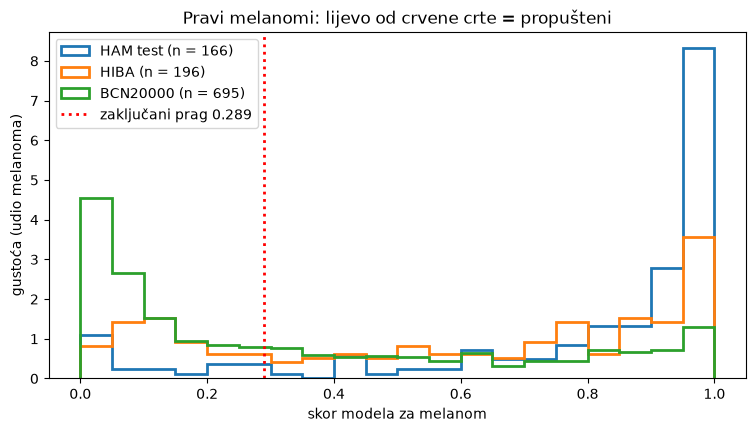

In [35]:
# ===== 13f. SKOR MODELA ZA PRAVE MELANOME U TRI SKUPA =====
fig, ax = plt.subplots(figsize=(9, 4.5))
for ime, df, boja in [("HAM test", test, "tab:blue"),
                      ("HIBA", hiba, "tab:orange"),
                      ("BCN20000", bcn, "tab:green")]:                    # tri skupa, svaki svoja boja
    skor = df[df["oznaka"] == 1]["p_melanom"]                     # samo pravi melanomi
    print(ime, "| melanoma:", len(skor), "| medijan skora:", round(skor.median(), 3))
    ax.hist(skor, bins=20, range=(0, 1), density=True, histtype="step",
            linewidth=2, color=boja, label=f"{ime} (n = {len(skor)})")    # obris histograma, udjeli

ax.axvline(PRAG, color="red", linestyle=":", linewidth=2, label=f"zaključani prag {PRAG:.3f}")   # lijevo = propušteni
ax.set_xlabel("skor modela za melanom")
ax.set_ylabel("gustoća (udio melanoma)")
ax.set_title("Pravi melanomi: lijevo od crvene crte = propušteni")
ax.legend(loc="upper left")
plt.savefig(REZ / "skor_melanoma_tri_skupa.png", dpi=150, bbox_inches="tight")   # spremi
plt.show()

In [36]:
# ===== 13g. PROVJERA NEOVISNOSTI SKUPOVA: postoje li iste slike ili lezije u više baza? =====
print("Primjeri identifikatora:")                                          # kako izgledaju oznake u svakoj bazi
print("  HAM  slika:", podjela["image_id"].iloc[0], "| lezija:", podjela["lesion_id"].iloc[0])
print("  HIBA slika:", hiba["isic_id"].iloc[0],     "| lezija:", hiba["lesion_id"].iloc[0])
print("  BCN  slika:", bcn_meta["isic_id"].iloc[0], "| lezija:", bcn_meta["lesion_id"].iloc[0])

print("\nZajedničke SLIKE (isti ISIC broj):")                              # isin -> True/False, sum -> broj pogodaka
print("  HAM10000 i HIBA:", podjela["image_id"].isin(hiba["isic_id"]).sum())
print("  HAM10000 i BCN :", podjela["image_id"].isin(bcn_meta["isic_id"]).sum())
print("  HIBA i BCN     :", hiba["isic_id"].isin(bcn_meta["isic_id"]).sum())

print("\nZajedničke LEZIJE:")                                              # isto za lezije
print("  HAM10000 i HIBA:", podjela["lesion_id"].isin(hiba["lesion_id"]).sum())
print("  HAM10000 i BCN :", podjela["lesion_id"].isin(bcn_meta["lesion_id"]).sum())
print("  HIBA i BCN     :", hiba["lesion_id"].isin(bcn_meta["lesion_id"]).sum())

Primjeri identifikatora:
  HAM  slika: ISIC_0027419 | lezija: HAM_0000118
  HIBA slika: ISIC_0079358 | lezija: IL_3989348
  BCN  slika: ISIC_0053453 | lezija: IL_0433332

Zajedničke SLIKE (isti ISIC broj):
  HAM10000 i HIBA: 0
  HAM10000 i BCN : 0
  HIBA i BCN     : 0

Zajedničke LEZIJE:
  HAM10000 i HIBA: 0
  HAM10000 i BCN : 0
  HIBA i BCN     : 0


HAM test  | Brier = 0.152 | referenca (bez modela) = 0.098
HIBA      | Brier = 0.136 | referenca (bez modela) = 0.130
BCN20000  | Brier = 0.116 | referenca (bez modela) = 0.123


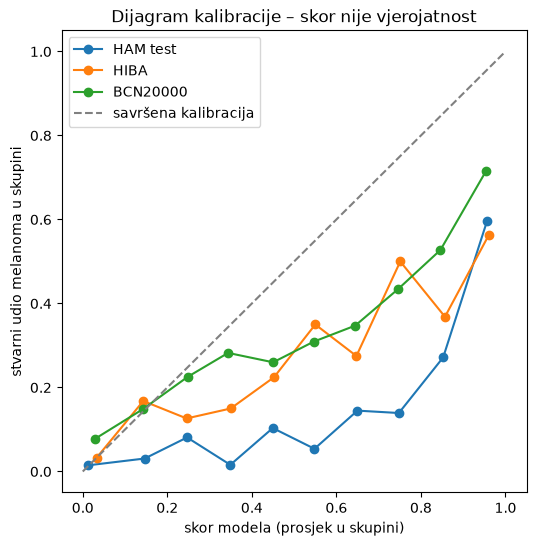

In [37]:
# ===== 13h. DIJAGRAM KALIBRACIJE I BRIER SCORE: znači li skor 0,7 zaista 70 % melanoma? =====
from sklearn.calibration import calibration_curve                        # podjela u skupine po skoru
from sklearn.metrics import brier_score_loss                             # prosječna kvadratna greška skora

fig, ax = plt.subplots(figsize=(6, 6))
for ime, df, boja in [("HAM test", test, "tab:blue"),
                      ("HIBA", hiba, "tab:orange"),
                      ("BCN20000", bcn, "tab:green")]:
    udio_melanoma, prosjecni_skor = calibration_curve(df["oznaka"], df["p_melanom"], n_bins=10)   # 10 skupina
    ax.plot(prosjecni_skor, udio_melanoma, "o-", color=boja, label=ime)   # točke spojene crtom

    brier = brier_score_loss(df["oznaka"], df["p_melanom"])             # 0 = savršeno; manje je bolje
    udio = df["oznaka"].mean()                                           # udio melanoma u skupu
    referenca = udio * (1 - udio)                                        # Brier "modela" koji svima kaže isti udio
    print(f"{ime:9} | Brier = {brier:.3f} | referenca (bez modela) = {referenca:.3f}")

ax.plot([0, 1], [0, 1], "--", color="gray", label="savršena kalibracija")   # dijagonala = savršeno
ax.set_xlabel("skor modela (prosjek u skupini)")
ax.set_ylabel("stvarni udio melanoma u skupini")
ax.set_title("Dijagram kalibracije – skor nije vjerojatnost")
ax.legend(loc="upper left")
plt.savefig(REZ / "kalibracija_tri_skupa.png", dpi=150, bbox_inches="tight")   # spremi
plt.show()

In [38]:
# ===== 13i. OSJETLJIVOST I SPECIFIČNOST ZA VIŠE PRAGOVA (eksploratorno – NE biramo novi prag) =====
pragovi_za_prikaz = [0.05, 0.10, 0.20, PRAG, 0.50]                       # zaključani prag je jedan od njih

redovi = []
for ime, df in [("HAM10000 test", test), ("HIBA", hiba), ("BCN20000", bcn)]:
    for p in pragovi_za_prikaz:
        odluka = (df["p_melanom"] >= p).astype(int)                       # odluka uz taj prag
        tn, fp, fn, tp = confusion_matrix(df["oznaka"], odluka, labels=[0, 1]).ravel()
        redovi.append({
            "skup": ime,
            "prag": round(p, 4),
            "osjetljivost": round(tp / (tp + fn), 3),
            "specifičnost": round(tn / (tn + fp), 3),
            "propušteni melanomi": fn,
            "lažne uzbune": fp,
            "upućivanja po melanomu": round((tp + fp) / tp, 1),
        })

tablica_pragova = pd.DataFrame(redovi)                                    # 3 skupa × 5 pragova = 15 redaka
tablica_pragova.to_csv(REZ / "tablica_pragova.csv", index=False, encoding="utf-8-sig")   # spremi
tablica_pragova                                                           # prikaz

,skup,prag,osjetljivost,specifičnost,propušteni melanomi,lažne uzbune,upućivanja po melanomu
0,HAM10000 test,0.0500,0.946,0.504,9,664,5.2
1,HAM10000 test,0.1000,0.934,0.556,11,594,4.8
2,HAM10000 test,0.2000,0.916,0.626,14,500,4.3
3,HAM10000 test,0.2894,0.886,0.673,19,437,4.0
4,HAM10000 test,0.5000,0.837,0.762,27,318,3.3
5,HIBA,0.0500,0.959,0.440,8,607,4.2
6,HIBA,0.1000,0.888,0.591,22,443,3.5
7,HIBA,0.2000,0.765,0.701,46,324,3.2
8,HIBA,0.2894,0.719,0.769,55,250,2.8
9,HIBA,0.5000,0.602,0.860,78,152,2.3


Učitan model iz epohe 6 (val_AUC=0.9017)


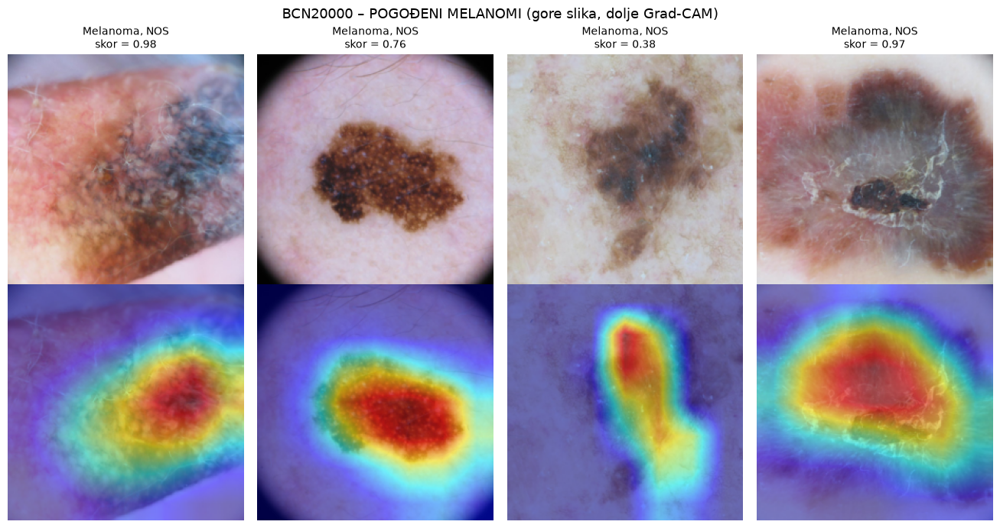

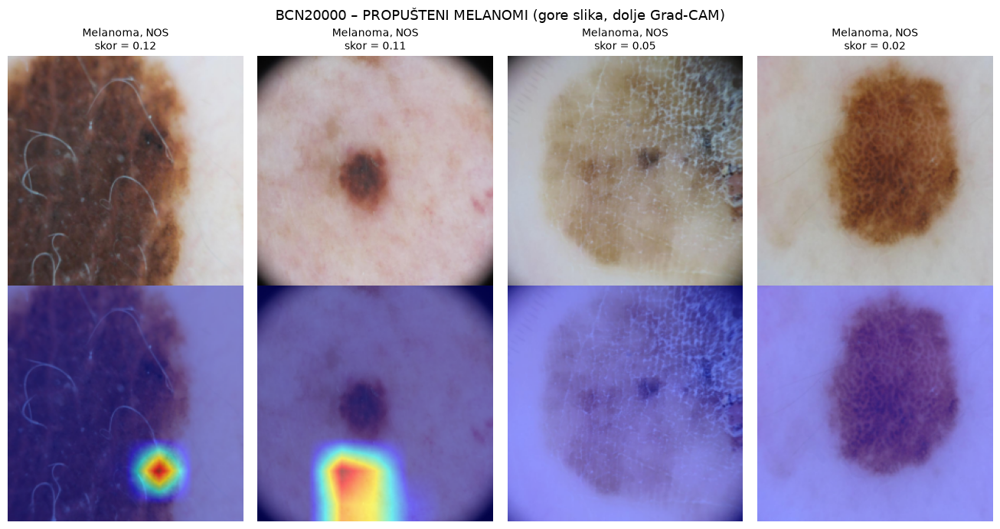

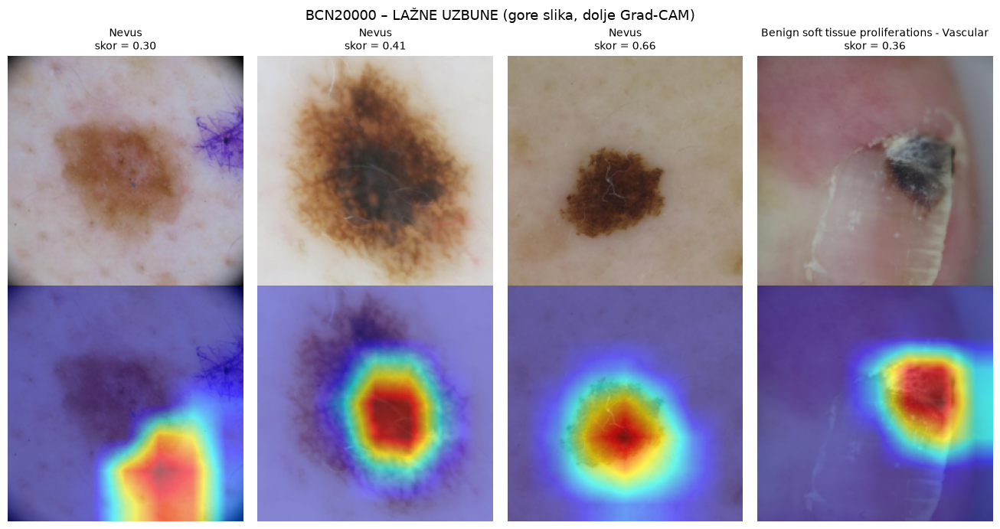

In [40]:
# ===== 13j. GRAD-CAM NA BCN20000 – gdje model gleda u trećem skupu podataka? =====
from pytorch_grad_cam import GradCAM                                       # Grad-CAM metoda
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget    # karta za klasu "melanom"
from pytorch_grad_cam.utils.image import show_cam_on_image                 # karta preko slike
from torchvision import transforms                                         # izrez slike za prikaz
from evaluate_melanom import load_model, get_eval_transform, MELANOM       # naš model i obrada

ANALIZA_DIR = REZ / "analiza_pogresaka"                                   # mapa za slike
ANALIZA_DIR.mkdir(parents=True, exist_ok=True)                            # napravi ako ne postoji
gc_model = load_model(torch.device("cpu"))                                # najbolji model
gc_transform = get_eval_transform()                                       # ista obrada kao na testu
izrez = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])   # isti izrez, za prikaz
cam = GradCAM(model=gc_model, target_layers=[gc_model.layer4[-1]])        # isti sloj kao u ćeliji 9b

bcn_putanje = {p.stem: p for p in BCN_DIR.rglob("*.jpg")}                 # kazalo: isic_id -> putanja
bcn["putanja"] = bcn["isic_id"].map(bcn_putanje)                          # dopiši putanju svakoj leziji

for naslov, uvjet, datoteka in [
        ("BCN20000 – POGOĐENI MELANOMI", (bcn["oznaka"] == 1) & (bcn["odluka"] == 1), "gradcam_tp_bcn.png"),
        ("BCN20000 – PROPUŠTENI MELANOMI", (bcn["oznaka"] == 1) & (bcn["odluka"] == 0), "gradcam_fn_bcn.png"),
        ("BCN20000 – LAŽNE UZBUNE", (bcn["oznaka"] == 0) & (bcn["odluka"] == 1), "gradcam_fp_bcn.png")]:
    primjeri = bcn[uvjet].sample(4, random_state=SEED)                    # 4 nasumična primjera (seed 42)
    fig, axes = plt.subplots(2, 4, figsize=(13.2, 7))                     # gore slika, dolje karta
    for j, (_, red) in enumerate(primjeri.iterrows()):
        slika = Image.open(red["putanja"]).convert("RGB")                           # otvori sliku
        x = gc_transform(slika).unsqueeze(0)                                        # ulaz za model
        karta = cam(input_tensor=x, targets=[ClassifierOutputTarget(MELANOM)])[0]   # toplinska karta
        rgb = np.array(izrez(slika), dtype=np.float32) / 255                        # slika, vrijednosti 0–1
        axes[0, j].imshow(rgb)                                                      # gore: slika
        axes[0, j].set_title(f'{red["dg"]}\nskor = {red["p_melanom"]:.2f}', fontsize=10)
        axes[1, j].imshow(show_cam_on_image(rgb, karta, use_rgb=True))              # dolje: slika s kartom
    for ax in axes.flatten():
        ax.axis("off")                                                    # bez osi
    plt.suptitle(naslov + " (gore slika, dolje Grad-CAM)", fontsize=13)
    plt.tight_layout()
    plt.savefig(ANALIZA_DIR / datoteka, dpi=150)                          # spremi
    plt.show()

In [41]:
# ===== 13k. JEDINICA EVALUACIJE: prva slika / nasumična slika / prosjek po leziji – sva tri skupa =====
# Naknadna analiza. Glavni BCN rezultat (prva slika po leziji) ostaje isti.
# Prvo pokretanje računa skor za SVE BCN slike (~17 000) – traje ~20–30 min; rezultat se sprema u CSV.
from evaluate_bcn import predict_bcn                                      # ista funkcija kao u završnom testu
from evaluate_melanom import load_model                                   # najbolji model

SVE_CSV = REZ / "bcn" / "predikcije_bcn_sve_slike.csv"                    # spremljeni skorovi svih BCN slika

if SVE_CSV.exists():                                                      # već izračunato -> samo učitaj
    bcn_sve = pd.read_csv(SVE_CSV)
else:
    # ista isključenja kao u ćeliji 10b: bez dijagnoze i metastaze melanoma
    bcn_sve = bcn_meta[bcn_meta["diagnosis_1"].notnull() &
                       (bcn_meta["diagnosis_3"] != "Melanoma metastasis")].copy()
    bcn_sve["oznaka"] = (bcn_sve["diagnosis_3"] == "Melanoma, NOS").astype(int)   # 1 = melanom
    bcn_sve = bcn_sve.reset_index(drop=True)                               # redni brojevi 0, 1, 2, …
    bcn_sve = predict_bcn(load_model(torch.device("cpu")), bcn_sve, torch.device("cpu"))   # skor za svaku sliku
    bcn_sve[["isic_id", "lesion_id", "oznaka", "p_melanom"]].to_csv(SVE_CSV, index=False)   # spremi

print("BCN slika:", len(bcn_sve), "| lezija:", bcn_sve["lesion_id"].nunique())   # očekujem 17157 / 4848

# kontrola: prva slika svake lezije mora imati isti skor kao u završnom testu (predikcije_bcn.csv)
prva = bcn_sve.drop_duplicates(subset="lesion_id").merge(bcn[["isic_id", "p_melanom"]], on="isic_id", suffixes=("", "_test"))
print("Kontrola – lezija:", len(prva), "| najveća razlika skora:", (prva["p_melanom"] - prva["p_melanom_test"]).abs().max())


def tri_protokola(df):
    # tri načina da jedna lezija dobije jedan skor
    prva_slika = df.drop_duplicates(subset="lesion_id")                                 # prva slika u tablici
    nasumicna = df.groupby("lesion_id", group_keys=False).sample(n=1, random_state=SEED)   # jedna nasumična (seed 42)
    prosjek = df.groupby(["lesion_id", "oznaka"])["p_melanom"].mean().reset_index()     # prosjek svih slika
    return [("prva slika", prva_slika), ("nasumična slika", nasumicna), ("prosjek po leziji", prosjek)]


redovi = []
for ime, df in [("HAM10000 test", test), ("HIBA", hiba), ("BCN20000", bcn_sve)]:
    for protokol, lez in tri_protokola(df):
        odluka = (lez["p_melanom"] >= PRAG).astype(int)                       # isti zaključani prag
        tn, fp, fn, tp = confusion_matrix(lez["oznaka"], odluka, labels=[0, 1]).ravel()
        redovi.append({
            "skup": ime,
            "protokol": protokol,
            "lezija": len(lez),
            "melanoma": tp + fn,
            "AUC": round(roc_auc_score(lez["oznaka"], lez["p_melanom"]), 3),
            "osjetljivost": round(tp / (tp + fn), 3),
            "osj. 95 % CI": wilson(tp, tp + fn),
            "specifičnost": round(tn / (tn + fp), 3),
            "spec. 95 % CI": wilson(tn, tn + fp),
        })

tablica_protokola = pd.DataFrame(redovi)                                  # 3 skupa × 3 protokola
tablica_protokola.to_csv(REZ / "tablica_protokola_lezija.csv", index=False, encoding="utf-8-sig")
tablica_protokola

Učitan model iz epohe 6 (val_AUC=0.9017)
BCN slika: 17157 | lezija: 4848
Kontrola – lezija: 4848 | najveća razlika skora: 0.0


,skup,protokol,lezija,melanoma,AUC,osjetljivost,osj. 95 % CI,specifičnost,spec. 95 % CI
0,HAM10000 test,prva slika,1121,92,0.922,0.902,0.824–0.948,0.753,0.726–0.779
1,HAM10000 test,nasumična slika,1121,92,0.919,0.902,0.824–0.948,0.753,0.726–0.779
2,HAM10000 test,prosjek po leziji,1121,92,0.926,0.902,0.824–0.948,0.750,0.723–0.776
3,HIBA,prva slika,1201,159,0.817,0.698,0.623–0.764,0.779,0.753–0.803
4,HIBA,nasumična slika,1201,159,0.814,0.698,0.623–0.764,0.779,0.753–0.803
5,HIBA,prosjek po leziji,1201,159,0.816,0.704,0.629–0.770,0.777,0.751–0.802
6,BCN20000,prva slika,4848,695,0.754,0.439,0.402–0.476,0.879,0.869–0.889
7,BCN20000,nasumična slika,4848,695,0.755,0.453,0.417–0.490,0.880,0.870–0.890
8,BCN20000,prosjek po leziji,4848,695,0.782,0.472,0.435–0.509,0.882,0.872–0.892


## 14. Usporedni modeli (unaprijed zapisani u dnevniku – naknadna analiza)
Glavni model (epoha 6) i prag 0,2894 ostaju glavni rezultat. Usporedni modeli biraju prag istim pravilom na HAM validaciji i **uspoređuju se na validaciji**; HAM test, HIBA i BCN samo se prikazuju (već viđeni skupovi).

Pokretanje: 14a (zapiše skriptu) → 14b (probni) → 14c, 14d (dugi treninzi; najbolje u VS Code terminalu: `conda activate rps`, pa `python train_usporedba.py zamrznuti`) → 14e, 14f (evaluacija) → 14g (logistička regresija) → 14h (tablica).

In [42]:
%%writefile train_usporedba.py
#
# USPOREDNI MODELI – unaprijed zapisani u dnevniku eksperimenata (11. 11. 2026.)
# Isti podaci (data_split), ista augmentacija, iste težine klasa, 10 epoha, najbolja epoha po validacijskom AUC-u.
#   zamrznuti  : ResNet-18 sa zamrznutim slojevima – uči se SAMO zadnji sloj (recept DL17/DL18), lr 1e-3
#   seed_123   : isti model kao glavni, samo drugi seed treninga (podjela podataka ostaje ista, seed 42)
#   seed_2024  : isto, seed 2024
# Pokretanje:  python train_usporedba.py zamrznuti          (pravo treniranje)
#              python train_usporedba.py zamrznuti probni   (kratki probni pokretaj)
# Glavni model (runs/melanom_resnet18) se NE dira.
#
import sys                                                # čitanje imena varijante iz naredbenog retka
import time                                               # mjerenje trajanja epohe
from pathlib import Path                                  # putanje

import torch                                              # PyTorch
import torch.nn as nn                                     # funkcija gubitka
from torch.utils.tensorboard import SummaryWriter         # zapis tijeka učenja

# sve ostalo uzimamo iz glavne skripte – isti podaci, ista augmentacija, isti model, ista validacija
from train_melanom import (set_seed, make_dataloaders_with_imagefolder, build_model,
                           evaluate_val, LEARNING_RATE, LOG_EVERY)


#
# GLOBALNE POSTAVKE
#
VARIJANTE = {                                   # ime varijante -> (seed treninga, stopa učenja, zamrznuti?)
    "zamrznuti": (42, 1e-3, True),              # samo zadnji sloj; veća stopa učenja jer uči samo 1026 težina
    "seed_123": (123, LEARNING_RATE, False),    # kao glavni model (lr 1e-4), drugi seed
    "seed_2024": (2024, LEARNING_RATE, False),  # kao glavni model, treći seed
}
EPOCHS = 10                                     # kao glavni model


def main() -> None:
    varijanta = sys.argv[1]                                     # npr. "zamrznuti"
    probni = len(sys.argv) > 2 and sys.argv[2] == "probni"    # True ako je dodano "probni"
    seed, lr, zamrznuti = VARIJANTE[varijanta]                  # postavke te varijante
    epohe = 1 if probni else EPOCHS                             # probni rad: 1 epoha
    max_batcheva = 30 if probni else None                       # probni rad: 30 batcheva

    run_dir = Path("runs") / ("usporedba_" + varijanta + ("_probni" if probni else ""))   # zasebna mapa
    set_seed(seed)                                                         # seed treninga
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Varijanta:", varijanta, "| seed:", seed, "| lr:", lr, "| zamrznuti:", zamrznuti, "| probni:", probni)

    run_dir.mkdir(parents=True, exist_ok=True)
    writer = SummaryWriter(log_dir=str(run_dir / "tb"))
    train_loader, val_loader, classes, class_weights = make_dataloaders_with_imagefolder()
    model = build_model(num_classes=len(classes)).to(device)               # ResNet-18, novi zadnji sloj

    if zamrznuti:                                       # recept s predavanja DL17/DL18
        for param in model.parameters():
            param.requires_grad = False                 # zamrzni sve težine
        for param in model.fc.parameters():
            param.requires_grad = True                  # odmrzni samo zadnji sloj (512 -> 2)

    ucenje = [p for p in model.parameters() if p.requires_grad]            # težine koje se uče
    print("Broj težina koje se uče:", sum(p.numel() for p in ucenje))
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))       # iste težine klasa
    optimizer = torch.optim.Adam(ucenje, lr=lr)                            # Adam samo za težine koje se uče

    global_step = 0
    best_val_auc = -1.0
    for epoch in range(1, epohe + 1):
        model.train()
        running_loss = 0.0
        start = time.time()

        for batch_idx, (x, y) in enumerate(train_loader, start=1):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            # Pet koraka učenja (isto kao glavni model):
            optimizer.zero_grad(set_to_none=True)   # 1. obriši stare gradijente
            logits = model(x)                       # 2. predviđanje
            loss = criterion(logits, y)             # 3. greška
            loss.backward()                         # 4. backpropagation
            optimizer.step()                        # 5. ažuriraj težine

            running_loss += loss.item()
            global_step += 1
            if batch_idx % LOG_EVERY == 0:
                writer.add_scalar("train/loss", running_loss / LOG_EVERY, global_step)
                running_loss = 0.0
            if max_batcheva is not None and batch_idx >= max_batcheva:     # probni rad: prekini
                break

        val = evaluate_val(model, val_loader, device)                      # validacija nakon epohe
        writer.add_scalar("val/auc", val["auc"], epoch)
        print(f"Epoch {epoch:02d}/{epohe} | val_AUC={val['auc']:.4f} | "
              f"osjetljivost@0.5={val['osjetljivost']:.3f} | specifičnost@0.5={val['specificnost']:.3f} | "
              f"{(time.time() - start) / 60:.1f} min")

        if val["auc"] >= best_val_auc:                                     # isto pravilo kao glavni model
            best_val_auc = val["auc"]
            torch.save({"model_state_dict": model.state_dict(), "num_classes": len(classes),
                        "classes": classes, "epoch": epoch, "val_auc": best_val_auc},
                       run_dir / "best_model.pt")
            print(f"   -> spremljen najbolji model (val_AUC={best_val_auc:.4f})")

    writer.close()
    print(f"Gotovo: {varijanta} | best val_AUC={best_val_auc:.4f} | model: {run_dir / 'best_model.pt'}")


if __name__ == "__main__":
    main()

Writing train_usporedba.py


In [43]:
# 14b. probni pokretaj zamrznute mreže (1 epoha, 30 batcheva, ~2 min)
!python train_usporedba.py zamrznuti probni

Varijanta: zamrznuti | seed: 42 | lr: 0.001 | zamrznuti: True | probni: True
Klase: {'0_ostalo': 0, '1_melanom': 1}
Trening slike po klasi: [6195, 783] | težine klasa: tensor([0.5632, 4.4559])
Split: train=6978, val=1533
Broj težina koje se uče: 1026
Epoch 01/1 | val_AUC=0.7090 | osjetljivost@0.5=0.951 | specifičnost@0.5=0.192 | 0.9 min
   -> spremljen najbolji model (val_AUC=0.7090)
Gotovo: zamrznuti | best val_AUC=0.7090 | model: runs\usporedba_zamrznuti_probni\best_model.pt


In [44]:
# 14c. zamrznuta mreža – pravo treniranje (~30–40 min na CPU)
!python train_usporedba.py zamrznuti

Varijanta: zamrznuti | seed: 42 | lr: 0.001 | zamrznuti: True | probni: False
Klase: {'0_ostalo': 0, '1_melanom': 1}
Trening slike po klasi: [6195, 783] | težine klasa: tensor([0.5632, 4.4559])
Split: train=6978, val=1533
Broj težina koje se uče: 1026
Epoch 01/10 | val_AUC=0.8214 | osjetljivost@0.5=0.963 | specifičnost@0.5=0.438 | 2.3 min
   -> spremljen najbolji model (val_AUC=0.8214)
Epoch 02/10 | val_AUC=0.8307 | osjetljivost@0.5=0.963 | specifičnost@0.5=0.428 | 2.5 min
   -> spremljen najbolji model (val_AUC=0.8307)
Epoch 03/10 | val_AUC=0.8437 | osjetljivost@0.5=0.689 | specifičnost@0.5=0.816 | 2.5 min
   -> spremljen najbolji model (val_AUC=0.8437)
Epoch 04/10 | val_AUC=0.8521 | osjetljivost@0.5=0.848 | specifičnost@0.5=0.682 | 2.5 min
   -> spremljen najbolji model (val_AUC=0.8521)
Epoch 05/10 | val_AUC=0.8468 | osjetljivost@0.5=0.963 | specifičnost@0.5=0.495 | 2.5 min
Epoch 06/10 | val_AUC=0.8525 | osjetljivost@0.5=0.823 | specifičnost@0.5=0.723 | 2.5 min
   -> spremljen najbol

In [45]:
# 14d. dva dodatna seeda glavnog modela (~2 × 50 min na CPU – može preko noći)
!python train_usporedba.py seed_123
!python train_usporedba.py seed_2024

Varijanta: seed_123 | seed: 123 | lr: 0.0001 | zamrznuti: False | probni: False
Klase: {'0_ostalo': 0, '1_melanom': 1}
Trening slike po klasi: [6195, 783] | težine klasa: tensor([0.5632, 4.4559])
Split: train=6978, val=1533
Broj težina koje se uče: 11177538
Epoch 01/10 | val_AUC=0.8647 | osjetljivost@0.5=0.665 | specifičnost@0.5=0.843 | 4.5 min
   -> spremljen najbolji model (val_AUC=0.8647)
Epoch 02/10 | val_AUC=0.8816 | osjetljivost@0.5=0.445 | specifičnost@0.5=0.958 | 4.8 min
   -> spremljen najbolji model (val_AUC=0.8816)
Epoch 03/10 | val_AUC=0.8995 | osjetljivost@0.5=0.726 | specifičnost@0.5=0.856 | 4.7 min
   -> spremljen najbolji model (val_AUC=0.8995)
Epoch 04/10 | val_AUC=0.8312 | osjetljivost@0.5=0.713 | specifičnost@0.5=0.788 | 4.8 min
Epoch 05/10 | val_AUC=0.9159 | osjetljivost@0.5=0.817 | specifičnost@0.5=0.817 | 4.9 min
   -> spremljen najbolji model (val_AUC=0.9159)
Epoch 06/10 | val_AUC=0.8812 | osjetljivost@0.5=0.744 | specifičnost@0.5=0.828 | 5.0 min
Epoch 07/10 | va

In [46]:
%%writefile evaluate_usporedba.py
#
# Evaluacija usporednih modela – ISTO PRAVILO kao glavni model:
# prag biran na HAM validaciji (najviši prag uz osjetljivost ≥ 95 %), zatim primijenjen na test, HIBA i BCN.
# Pokretanje: python evaluate_usporedba.py glavni | zamrznuti | seed_123 | seed_2024
# Rezultati: rezultati/usporedba/metrike_<varijanta>.csv  (glavni rezultati i prag.json se NE diraju)
#
import sys                                     # ime varijante iz naredbenog retka
from pathlib import Path                       # putanje

import pandas as pd                            # tablice
import torch                                   # PyTorch
import torch.nn as nn                          # zadnji sloj
from torchvision.models import resnet18        # ResNet-18

from evaluate_melanom import predict, odaberi_prag, izracunaj_metrike, VAL_DIR, TEST_DIR   # isti postupak
from evaluate_hiba import predict_hiba, ucitaj_hiba                                        # HIBA
from evaluate_bcn import predict_bcn, BCN_POPIS                                            # BCN (1 slika po leziji)

REZ_DIR = Path("rezultati") / "usporedba"      # zasebna mapa za usporedbe


def ucitaj_model(putanja, device):
    ckpt = torch.load(putanja, map_location=device)                        # spremljeni rječnik
    model = resnet18(weights=None)                                         # prazan ResNet-18
    model.fc = nn.Linear(model.fc.in_features, ckpt["num_classes"])        # zadnji sloj 512 -> 2
    model.load_state_dict(ckpt["model_state_dict"])                        # naučene težine
    model.to(device)
    model.eval()
    print(f"Učitan {putanja} (epoha {ckpt['epoch']}, val_AUC={ckpt['val_auc']:.4f})")
    return model


def main():
    varijanta = sys.argv[1]                                                # npr. "zamrznuti"
    if varijanta == "glavni":
        putanja = Path("runs") / "melanom_resnet18" / "best_model.pt"      # glavni model (seed 42)
    else:
        putanja = Path("runs") / ("usporedba_" + varijanta) / "best_model.pt"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    REZ_DIR.mkdir(parents=True, exist_ok=True)

    model = ucitaj_model(putanja, device)
    df_val = predict(model, VAL_DIR, device)                               # skorovi na validaciji
    prag = odaberi_prag(df_val)                                            # isto pravilo: osjetljivost ≥ 95 %
    print(f"Prag (validacija): {prag:.4f}")

    skupovi = [("HAM validacija", df_val),
               ("HAM test", predict(model, TEST_DIR, device)),
               ("HIBA", predict_hiba(model, ucitaj_hiba(), device)),
               ("BCN20000", predict_bcn(model, pd.read_csv(BCN_POPIS), device))]

    redovi = []
    for ime, df in skupovi:
        m = izracunaj_metrike(df, prag)                                    # iste formule kao za glavni model
        m["skup"] = ime
        m["model"] = varijanta
        redovi.append(m)
    tablica = pd.DataFrame(redovi)
    print("\n" + tablica.to_string(index=False))
    tablica.to_csv(REZ_DIR / f"metrike_{varijanta}.csv", index=False)
    print(f"\nSpremljeno: {REZ_DIR / f'metrike_{varijanta}.csv'}")


if __name__ == "__main__":
    main()

Writing evaluate_usporedba.py


In [47]:
# 14f. evaluacija: glavni model (kontrola – mora dati prag 0,2894) i usporedni modeli (~8 min svaki)
!python evaluate_usporedba.py glavni
!python evaluate_usporedba.py zamrznuti
!python evaluate_usporedba.py seed_123
!python evaluate_usporedba.py seed_2024

Učitan runs\melanom_resnet18\best_model.pt (epoha 6, val_AUC=0.9017)
Prag (validacija): 0.2894

  prag  TP  FN   TN  FP  osjetljivost  specificnost  preciznost     F1  balanced_acc  tocnost    AUC           skup  model
0.2894 156   8  892 477        0.9512        0.6516      0.2464 0.3915        0.8014   0.6836 0.9017 HAM validacija glavni
0.2894 147  19  901 437        0.8855        0.6734      0.2517 0.3920        0.7795   0.6968 0.8942       HAM test glavni
0.2894 141  55  834 250        0.7194        0.7694      0.3606 0.4804        0.7444   0.7617 0.8232           HIBA glavni
0.2894 305 390 3652 501        0.4388        0.8794      0.3784 0.4064        0.6591   0.8162 0.7542       BCN20000 glavni

Spremljeno: rezultati\usporedba\metrike_glavni.csv
Učitan runs\usporedba_zamrznuti\best_model.pt (epoha 8, val_AUC=0.8525)
Prag (validacija): 0.3455

  prag  TP  FN   TN   FP  osjetljivost  specificnost  preciznost     F1  balanced_acc  tocnost    AUC           skup     model
0.3455 156 

In [48]:
# ===== 14g. OSNOVNA LINIJA: logistička regresija na histogramu boja (ML + CV) =====
# Pitanje: koliko se može samo iz raspodjele boja, bez dubokog učenja?
from sklearn.linear_model import LogisticRegression                      # ML: logistička regresija
from sklearn.preprocessing import StandardScaler                         # ML: standardizacija značajki
from evaluate_melanom import odaberi_prag, izracunaj_metrike             # isto pravilo i iste formule
USP_DIR = REZ / "usporedba"                                               # mapa za usporedbe
USP_DIR.mkdir(parents=True, exist_ok=True)


def histogram_boja(putanja, bins=8):
    # 24 značajke: za svaki kanal (R, G, B) udio piksela u 8 razreda svjetline (CV: histogram)
    slika = np.array(Image.open(putanja).convert("RGB").resize((224, 224)))   # ista veličina za sve
    znacajke = []
    for kanal in range(3):                                                # R, G, B
        h, _ = np.histogram(slika[:, :, kanal], bins=bins, range=(0, 256))   # broj piksela po razredu
        znacajke.extend(h / h.sum())                                      # udjeli (zbroj = 1)
    return znacajke


def tablica_iz_mape(mapa):
    # slike iz data_split/<skup>/<klasa> -> tablica (putanja, oznaka)
    redovi = []
    for klasa, oznaka in [("0_ostalo", 0), ("1_melanom", 1)]:
        for p in sorted((mapa / klasa).glob("*.jpg")):
            redovi.append({"putanja": p, "oznaka": oznaka})
    return pd.DataFrame(redovi)


# 1) skupovi: HAM trening / validacija / test iz data_split; HIBA i BCN iz spremljenih tablica
ham_train = tablica_iz_mape(Path("data_split") / "train")
ham_val = tablica_iz_mape(Path("data_split") / "val")
ham_test = tablica_iz_mape(Path("data_split") / "test")
hiba_lr = hiba[["isic_id", "oznaka"]].copy()
hiba_lr["putanja"] = hiba_lr["isic_id"].map({p.stem: p for p in HIBA_DIR.rglob("*.jpg")})
bcn_lr = bcn[["isic_id", "oznaka"]].copy()
bcn_lr["putanja"] = bcn_lr["isic_id"].map({p.stem: p for p in BCN_DIR.rglob("*.jpg")})

# 2) značajke (histogrami) – traje nekoliko minuta
skupovi_lr = [("HAM trening", ham_train), ("HAM validacija", ham_val), ("HAM test", ham_test),
              ("HIBA", hiba_lr), ("BCN20000", bcn_lr)]
X = {}
for ime, df in skupovi_lr:
    X[ime] = np.array([histogram_boja(p) for p in df["putanja"]])         # matrica: slike × 24 značajke
    print(ime, X[ime].shape)

# 3) treniranje SAMO na HAM treningu (težine klasa kao kod ResNeta: class_weight="balanced")
skaler = StandardScaler().fit(X["HAM trening"])                           # srednja vrijednost i SD iz treninga
logreg = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
logreg.fit(skaler.transform(X["HAM trening"]), ham_train["oznaka"])

# 4) skor za melanom + prag istim pravilom na validaciji (osjetljivost ≥ 95 %)
for ime, df in skupovi_lr:
    df["p_melanom"] = logreg.predict_proba(skaler.transform(X[ime]))[:, 1]   # predict_proba[:, 1] (ML5)
prag_lr = odaberi_prag(ham_val)
print(f"\nPrag (validacija): {prag_lr:.4f}")

redovi = []
for ime, df in skupovi_lr[1:]:                                            # bez trening skupa
    m = izracunaj_metrike(df, prag_lr)
    m["skup"] = ime
    m["model"] = "logreg_boje"
    redovi.append(m)
metrike_lr = pd.DataFrame(redovi)
metrike_lr.to_csv(USP_DIR / "metrike_logreg_boje.csv", index=False)
metrike_lr

HAM trening (6978, 24)
HAM validacija (1533, 24)
HAM test (1504, 24)
HIBA (1280, 24)
BCN20000 (4848, 24)

Prag (validacija): 0.3505


,prag,TP,FN,TN,FP,osjetljivost,specificnost,preciznost,F1,balanced_acc,tocnost,AUC,skup,model
0,0.3505,156,8,670,699,0.9512,0.4894,0.1825,0.3062,0.7203,0.5388,0.7770,HAM validacija,logreg_boje
1,0.3505,140,26,667,671,0.8434,0.4985,0.1726,0.2866,0.6709,0.5366,0.7224,HAM test,logreg_boje
2,0.3505,176,20,161,923,0.8980,0.1485,0.1601,0.2718,0.5232,0.2633,0.6597,HIBA,logreg_boje
3,0.3505,685,10,91,4062,0.9856,0.0219,0.1443,0.2517,0.5038,0.1601,0.6015,BCN20000,logreg_boje


In [49]:
# ===== 14h. USPOREDNA TABLICA: osnovna linija / zamrznuta mreža / naš model (3 seeda) =====
USP_DIR = REZ / "usporedba"
sve = pd.concat([pd.read_csv(p) for p in sorted(USP_DIR.glob("metrike_*.csv"))])   # sve spremljene usporedbe

# a) AUC i osjetljivost (uz prag svakog modela s njegove validacije) – modeli u redcima, skupovi u stupcima
redoslijed = ["HAM validacija", "HAM test", "HIBA", "BCN20000"]
auc = sve.pivot(index="model", columns="skup", values="AUC")[redoslijed]
osj = sve.pivot(index="model", columns="skup", values="osjetljivost")[redoslijed]
print("AUC:\n", auc.round(3), "\n")
print("Osjetljivost (prag s vlastite validacije):\n", osj.round(3), "\n")

# b) naš model kroz 3 seeda: srednja vrijednost ± SD
seedovi = sve[sve["model"].isin(["glavni", "seed_123", "seed_2024"])]
stabilnost = seedovi.groupby("skup")[["AUC", "osjetljivost", "specificnost"]].agg(["mean", "std"]).round(3)
print("Naš model, 3 seeda (srednja vrijednost i SD):\n", stabilnost.loc[redoslijed])

auc.to_csv(USP_DIR / "usporedba_auc.csv", encoding="utf-8-sig")
stabilnost.to_csv(USP_DIR / "stabilnost_seedovi.csv", encoding="utf-8-sig")

AUC:
 skup         HAM validacija  HAM test   HIBA  BCN20000
model                                                 
glavni                0.902     0.894  0.823     0.754
logreg_boje           0.777     0.722  0.660     0.602
seed_123              0.916     0.895  0.818     0.728
seed_2024             0.912     0.920  0.820     0.685
zamrznuti             0.852     0.826  0.733     0.639 

Osjetljivost (prag s vlastite validacije):
 skup         HAM validacija  HAM test   HIBA  BCN20000
model                                                 
glavni                0.951     0.886  0.719     0.439
logreg_boje           0.951     0.843  0.898     0.986
seed_123              0.951     0.855  0.699     0.479
seed_2024             0.951     0.946  0.719     0.432
zamrznuti             0.951     0.898  0.719     0.632 

Naš model, 3 seeda (srednja vrijednost i SD):
                   AUC        osjetljivost        specificnost       
                 mean    std         mean    std         mea

# 15. Zaključak i ograničenja

## Glavni nalaz
Jedan model (ResNet-18, prijenosno učenje) i **isti prag odluke (0,289, najviši prag uz osjetljivost ≥ 95 % na HAM validaciji)** primijenjeni su na tri skupa podataka:

| skup podataka | jedinica | udio melanoma | AUC | osjetljivost (95 % CI) | specifičnost | preciznost |
|---|---|---|---|---|---|---|
| HAM10000 test (isti izvor kao trening) | slika | 11,0 % | 0,894 | 0,886 (0,83–0,93) | 0,673 | 0,252 |
| HIBA (Buenos Aires) | slika | 15,3 % | 0,823 | 0,719 (0,65–0,78) | 0,769 | 0,361 |
| BCN20000 (Barcelona) | jedna slika po leziji | 14,3 % | 0,754 | 0,439 (0,40–0,48) | 0,879 | 0,378 |

**Uspjeh na testu iz istog izvora ne jamči jednak rad u drugoj ustanovi:** osjetljivost pri istom pragu pada s 88,6 % na 71,9 % i 43,9 %. Razlike su velike, ali ih treba tumačiti uz različit sastav skupova (udio melanoma, vrste lezija), različite jedinice evaluacije i činjenicu da slike iste lezije ili pacijenta nisu neovisna opažanja. Zato su intervali po slici samo okvirni. Preciznost ovisi i o udjelu melanoma u skupu.

**Prag nije držao ni na izvornom izvoru:** na validaciji je osjetljivost 95,1 %, a na HAM testu 88,6 %. Prag je odabran na samo 164 melanoma, pa i sam ima slučajnu nesigurnost.

## Dodatne analize
- **Rezultati po leziji** (prosjek skora slika iste lezije), HAM / HIBA: **AUC** 0,926 / 0,816; **osjetljivost** 0,902 / 0,704. Slijede isti obrazac kao rezultati po slici.
- **Lokalna prilagodba praga odluke na HIBA-i** (polovica pacijenata za odabir, polovica za provjeru) povećala je osjetljivost sa 73,7 % na 92,6 %, uz pad specifičnosti sa 76,0 % na 50,1 %. To je kompromis između propuštenih melanoma i lažnih uzbuna. Rezultat je u skladu s pomakom domene, ali ga sam po sebi ne dokazuje.
- **Skor pravih melanoma** (medijan): HAM 0,93, HIBA 0,65, BCN 0,23. Na BCN-u velik dio melanoma ima nizak skor. Snižavanje praga može povećati osjetljivost (na BCN-u s 30,9 % pri pragu 0,5 na 43,9 % pri 0,289), ali uz više lažno pozitivnih nalaza. Niži AUC pokazuje da problem nije samo u izboru praga. Mogući smjer poboljšanja je treniranje na podacima iz više ustanova.
- **Propušteni melanomi:** u opisnim tablicama nisu uočene velike razlike po spolu, a na BCN-u ni po regiji tijela. Medijan dobi propuštenih melanoma je niži (HAM 50 prema 65, BCN 60 prema 65), no na HAM-u je propuštenih samo 19, pa je to opis, a ne potvrđen nalaz.
- **Kalibracija:** model precjenjuje rizik. Težine klasa mogu tome pridonijeti, ali njihov udio nije zasebno ispitan (nema usporednog treniranja bez težina). Zato se izlaz naziva **skorom modela**, a ne vjerojatnošću.
- **Više pragova (eksploratorno):** na HIBA-i prag 0,05 daje osjetljivost 0,959 uz specifičnost 0,440; na BCN-u ni prag 0,05 ne doseže 95 % (osjetljivost 0,773 uz specifičnost 0,578 i 1 753 lažne uzbune). Na BCN-u je cijena svakog dodatno pronađenog melanoma vrlo visoka.
- **Jedinica evaluacije:** na BCN-u nasumično odabrana slika po leziji daje gotovo isti rezultat kao prva slika (osjetljivost 0,453 prema 0,439; AUC 0,755 prema 0,754), pa izbor „prve slike” nije iskrivio rezultat. Prosjek svih slika lezije nešto je bolji (AUC 0,782; osjetljivost 0,472). Na HAM-u i HIBA-i sva tri protokola daju gotovo iste rezultate.
- **Brier score** (manje je bolje): HAM test 0,152 (referenca bez modela 0,098), HIBA 0,136 (0,130), BCN 0,116 (0,123). Kao procjena vjerojatnosti skor nije bolji od jednostavnog udjela melanoma, što potvrđuje da ga ne treba tumačiti kao vjerojatnost; model ipak dobro **razlikuje** melanom od ostalog (AUC).
- **Grad-CAM** pokazuje *gdje* model gleda: kod pronađenih melanoma (HAM, HIBA i BCN) uglavnom na leziji, a kod propuštenih često nigdje ili pored lezije. Ne dokazuje da prepoznaje medicinski relevantne znakove.
- **Preklapanje skupova:** nisu pronađene zajedničke slike (ISIC broj) između HAM10000, HIBA i BCN20000, niti zajedničke lezije prema identifikatorima. Identifikatori lezija nisu isti sustav označavanja, pa dupliciranje sadržaja pod različitim oznakama nije isključeno.

## Usporedni modeli (unaprijed zapisani, uspoređeni na validaciji)
| model | AUC validacija | AUC HAM test | AUC HIBA | AUC BCN |
|---|---|---|---|---|
| logistička regresija na histogramu boja | 0,777 | 0,722 | 0,660 | 0,602 |
| ResNet-18, zamrznut (uči se samo zadnji sloj) | 0,852 | 0,826 | 0,733 | 0,639 |
| **ResNet-18, cijela mreža – glavni model (seed 42)** | **0,902** | **0,894** | **0,823** | **0,754** |
| ResNet-18, cijela mreža – 3 seeda (srednja vrijednost ± SD) | 0,910 ± 0,007 | 0,903 ± 0,015 | 0,821 ± 0,003 | 0,722 ± 0,035 |

- **Duboko učenje vrijedi:** sama raspodjela boja daje znatno niži AUC. Model na bojama uz svoj prag na BCN-u označava gotovo sve slike (specifičnost 0,02), jer se boje snimaka razlikuju između ustanova.
- **Fino podešavanje cijele mreže opravdano je na validaciji** (AUC 0,902 prema 0,852 za zamrznutu mrežu).
- **Glavni model je reprezentativan:** po validacijskom AUC-u najslabiji je od tri seeda, pa nije „sretno izabran”. Na BCN-u mu je AUC najviši od tri (0,754; raspon 0,685–0,754), pa je realnija procjena za BCN srednja vrijednost 0,722.
- **Prag je nestabilan između treninga:** isto pravilo (≥ 95 % na validaciji) dalo je pragove 0,289, 0,280 i 0,139, a osjetljivost na HAM testu 0,886, 0,855 i 0,946. Prag treba odrediti za svaki model posebno i ne smije se prenositi bez provjere.

## Razvoj verzija
| faza | što je učinjeno | status evaluacije |
|---|---|---|
| Verzija 1 | prvi razvoj, pregled HAM i HIBA rezultata | razvojni rezultati |
| Verzija 2 | nove odluke definirane prije njezine evaluacije (cilj osjetljivosti 95 %) | ponovna provjera na već viđenim skupovima |
| Završna evaluacija | zaključani model i prag primijenjeni na BCN20000 | jedini potpuno neviđen skup |
| Naknadne analize | dodatne analize i usporedni modeli nakon recenzija (unaprijed zapisani u dnevniku) | opisne; ne mijenjaju glavni model ni prag |

HAM test i HIBA viđeni su u verziji 1, pa nisu potpuno netaknuti. Samo je BCN20000 ostao nedirnut do završne evaluacije (detalji: `DNEVNIK_EKSPERIMENATA.md`).

## Ograničenja
- Model je **binaran**: melanom nasuprot svemu ostalom. „Ostalo” uključuje i maligne promjene (BCC, SCC).
- Podaci su retrospektivni, javni i pretežno sa svijetle kože (HAM: Austrija i Australija). Tipovi kože V–VI nisu zastupljeni, a III–IV na HIBA-i ima samo 17 melanoma.
- Prag je odabran na jednom skupu (HAM validacija) i ne prenosi se na druge ustanove.
- Podjela je po leziji, ne po pacijentu (HAM10000 nema oznaku pacijenta).
- Oznake nevusa dijelom su bez histološke potvrde.
- Glavni rezultat je iz jednog treninga (seed 42); tri seeda pokazuju stabilan AUC na HAM-u i HIBA-i, ali veće razlike na BCN-u i u pragu.
- Intervali pouzdanosti po slici ne uzimaju u obzir ovisnost slika iste lezije ili pacijenta.
- Model nije validiran u kliničkom radu i ne zamjenjuje dermatologa ni patohistologiju. Projekt je isključivo edukacijski.

## Moguća poboljšanja
Bootstrap intervali po leziji ili pacijentu; kalibracija skora na lokalnim podacima; normalizacija boje i veća rezolucija; treniranje na podacima iz više ustanova (pravo rješenje za pad na BCN-u, ali tada nema neovisnog vanjskog testa).
